# Final Network Evaluation

Проверка финальной `GraphPolicyValueNetV2` без чтения сохранённых NPZ state-файлов.

Validation states восстанавливаются прямым replay Teacher trajectory из raw GridFM scenarios.
Поэтому notebook не зависит от `state_path` в `examples_val.csv`.

Что здесь есть:

- история обучения из TensorBoard;
- Value Head: MAE, RMSE, R², Pearson, Spearman;
- Policy Head: Top-1 / Top-3 / Top-5, STOP и Switch accuracy;
- отдельные результаты для simple / medium / hard;
- шкала Value как evaluation bar;
- Top действий самой сети;
- Top действий MCTS с visits, Q и prior;
- схема IEEE-118 с отмеченными предлагаемыми ветвями;
- полный MCTS rollout;
- J до/после переключений;
- terminal redispatch;
- end-to-end evaluation;
- сравнение Network + MCTS с Teacher.

## 1. Пути и параметры

In [15]:
from pathlib import Path

PROJECT_DIR = Path(r"D:/projects/PowerGridReconfig")

DATASET_DIR = PROJECT_DIR / "data/paper/dataset/case118_17k_v2"
SOURCE_DIR = PROJECT_DIR / "data/paper/gridfm_generated/case118_17k"

TRAIN_CSV = DATASET_DIR / "examples_train.csv"
VAL_CSV = DATASET_DIR / "examples_val.csv"
RAW_DIR = SOURCE_DIR / "raw"

MODEL_DIR = PROJECT_DIR / "data/paper/models/case118_17k_v2"
CHECKPOINT = MODEL_DIR / "graph_policy_value_net.pt"

TENSORBOARD_DIR = MODEL_DIR / "tensorboard/case118_17k_v2"

SIMULATIONS = 150
DEPTH = 4
MAX_STEPS = 5
TOP_K = 30

C_PUCT = 2.0
FPU_VALUE = -0.25
PRIOR_EXPONENT = 0.5
WIDENING_COEFFICIENT = 2.0
WIDENING_EXPONENT = 0.5
EXPLORATION_QUOTA = 2

STOP_POLICY = "no_hard_overloads"
RANDOM_SEED = 42

# Подробно показать этот validation scenario.
SCENARIO_ID = 12754

# End-to-end benchmark: 10 simple + 10 medium + 10 hard.
EVAL_PER_DIFFICULTY = 10

## 2. Imports

In [16]:
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import torch

from IPython.display import display
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

from grid_topology_ai.actions import (
    GridFMActionSpace,
    make_do_nothing_action,
)
from grid_topology_ai.data import GridFMAdapter
from grid_topology_ai.environment import TopologySwitchingEnv
from grid_topology_ai.evaluator import NeuralPolicyValueEvaluator
from grid_topology_ai.physics.objective import assess_physical_state
from grid_topology_ai.physics.redispatch import run_minimal_ac_redispatch
from grid_topology_ai.physics.utility import (
    GridFMReward,
    state_security_penalty,
)
from grid_topology_ai.power_flow.backend import GridFMPowerFlowBackend
from grid_topology_ai.search.mcts import (
    MCTSConfig,
    MCTSPlanner,
    normalize_policy,
    select_action_from_policy,
)
from grid_topology_ai.state import BRANCH_FEATURE_COLUMNS

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DIFFICULTIES = ["simple", "medium", "hard"]

plt.rcParams["figure.figsize"] = (10, 5.5)
plt.rcParams["figure.dpi"] = 120

print("Device:", DEVICE)

Device: cuda


## 3. Checkpoint и validation data

In [17]:
checkpoint = torch.load(
    CHECKPOINT,
    map_location="cpu",
    weights_only=False,
)

train_examples = pd.read_csv(TRAIN_CSV)
val_examples = pd.read_csv(VAL_CSV)

info = pd.DataFrame(
    {
        "value": [
            checkpoint.get("model_type"),
            checkpoint.get("hidden_dim"),
            checkpoint.get("num_layers"),
            checkpoint.get("dropout"),
            checkpoint.get("completed_epoch"),
            checkpoint.get("best_epoch"),
            checkpoint.get("best_metric"),
            len(train_examples),
            len(val_examples),
        ]
    },
    index=[
        "model_type",
        "hidden_dim",
        "num_layers",
        "dropout",
        "completed_epoch",
        "best_epoch",
        "best_metric",
        "train_rows",
        "validation_rows",
    ],
)

display(info)

,value
model_type,graph_policy_value_net_v2
hidden_dim,128
num_layers,3
dropout,0.0
completed_epoch,None
best_epoch,19
best_metric,1.292977
train_rows,37390
validation_rows,7527


## 4. История обучения

Здесь читается TensorBoard, а не `training_metrics.csv`.

При resume текущий training logger заново создаёт metrics CSV, поэтому в нём может
остаться только последняя часть обучения. TensorBoard event-файлы сохраняют историю.

In [18]:
tags = {
    "loss/train_total": "train_loss",
    "loss/val_total": "val_loss",
    "loss/train_policy": "train_policy",
    "loss/val_policy": "val_policy",
    "loss/train_value": "train_value",
    "loss/val_value": "val_value",
    "accuracy/val_top1": "val_top1",
    "accuracy/val_top3": "val_top3",
    "accuracy/val_top5": "val_top5",
    "accuracy/val_stop": "val_stop",
    "accuracy/val_switch": "val_switch",
}

history = {}

event_files = sorted(
    TENSORBOARD_DIR.glob("events.out.tfevents.*"),
    key=lambda path: path.stat().st_mtime,
)

for event_file in event_files:
    events = EventAccumulator(str(event_file))
    events.Reload()

    scalar_tags = events.Tags()["scalars"]

    for tag, column in tags.items():
        if tag not in scalar_tags:
            continue

        for item in events.Scalars(tag):
            history.setdefault(int(item.step), {})[column] = float(item.value)

history = (
    pd.DataFrame.from_dict(history, orient="index")
    .sort_index()
    .rename_axis("epoch")
    .reset_index()
)

display(history.tail(10))

,epoch,train_loss,val_loss,train_policy,val_policy,train_value,val_value,val_top1,val_top3,val_top5,val_stop,val_switch
26,27,1.020106,1.331155,1.018033,1.328672,0.002073,0.002483,0.633320,0.846552,0.903946,0.762170,0.587579
27,28,1.014069,1.304044,1.011859,1.301985,0.002210,0.002059,0.648466,0.855454,0.908197,0.898073,0.559856
28,29,1.003333,1.313663,1.001263,1.311313,0.002071,0.002350,0.648864,0.857447,0.911651,0.893509,0.562016
29,30,0.997408,1.376468,0.995314,1.374250,0.002094,0.002217,0.639697,0.847217,0.907533,0.886917,0.551935
30,31,0.984742,1.361340,0.982734,1.359223,0.002008,0.002117,0.647137,0.847217,0.910456,0.910751,0.553555
31,32,0.979530,1.315282,0.977443,1.313283,0.002088,0.002000,0.654710,0.853859,0.909659,0.909229,0.564356
32,33,0.960842,1.363247,0.958866,1.361157,0.001976,0.002090,0.638236,0.846552,0.907666,0.845842,0.564536
33,34,0.963821,1.335287,0.961834,1.333220,0.001987,0.002067,0.651654,0.849608,0.907666,0.902130,0.562736
34,35,0.948954,1.383834,0.946931,1.381249,0.002023,0.002585,0.641026,0.851734,0.909127,0.871704,0.559136
35,36,0.944694,1.339042,0.942720,1.336843,0.001973,0.002200,0.645676,0.846685,0.907666,0.816937,0.584879


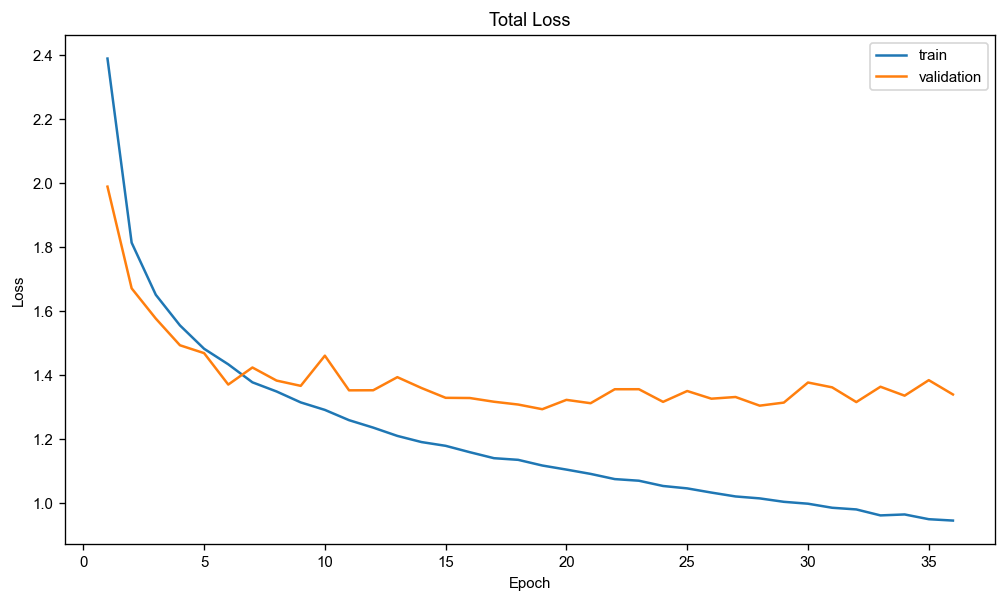

In [19]:
fig, ax = plt.subplots()

ax.plot(history["epoch"], history["train_loss"], label="train")
ax.plot(history["epoch"], history["val_loss"], label="validation")

ax.set_title("Total Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend()

plt.show()

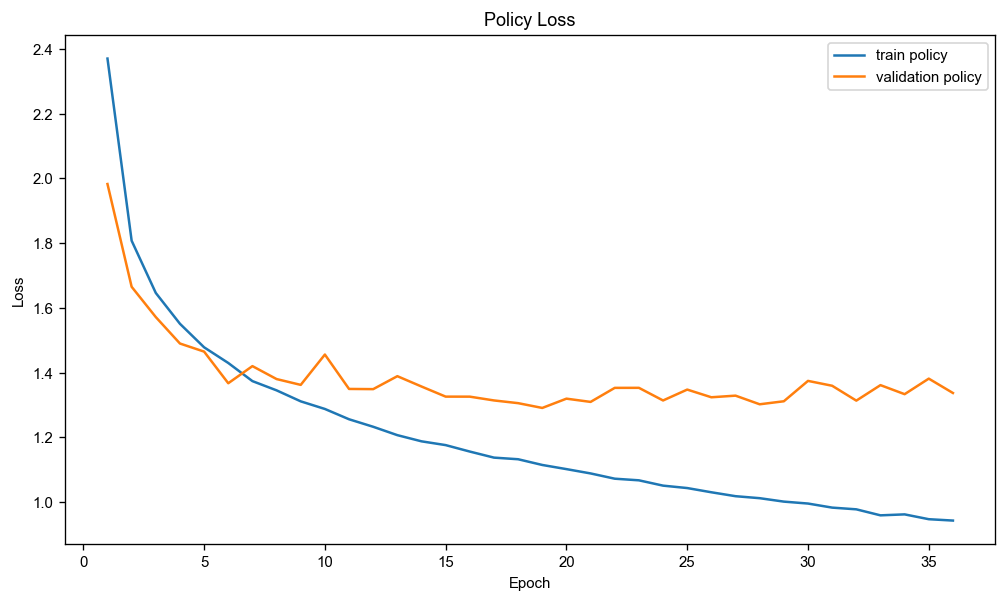

In [20]:
fig, ax = plt.subplots()

ax.plot(history["epoch"], history["train_policy"], label="train policy")
ax.plot(history["epoch"], history["val_policy"], label="validation policy")

ax.set_title("Policy Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend()

plt.show()

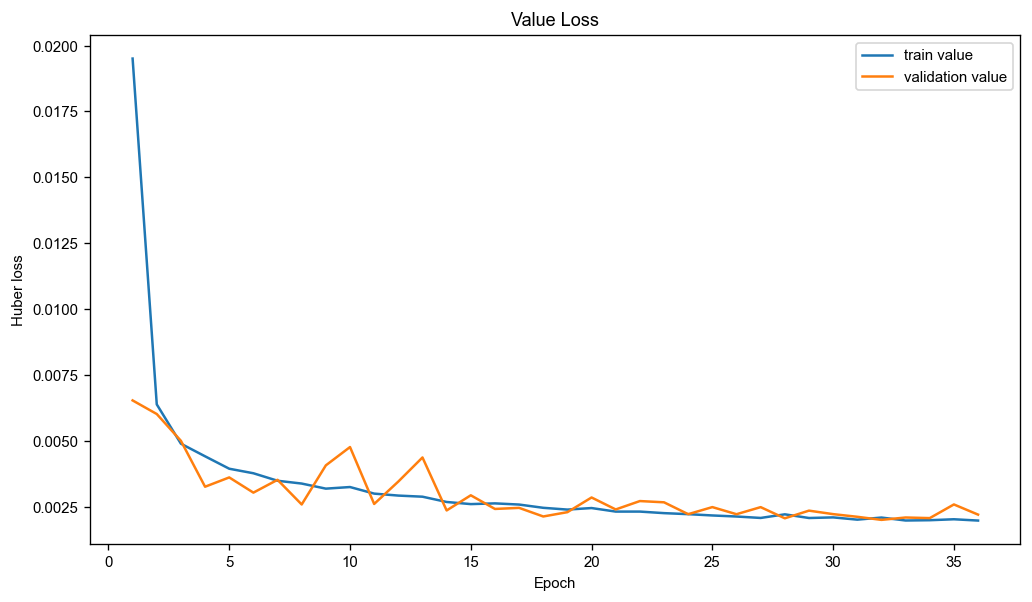

In [21]:
fig, ax = plt.subplots()

ax.plot(history["epoch"], history["train_value"], label="train value")
ax.plot(history["epoch"], history["val_value"], label="validation value")

ax.set_title("Value Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Huber loss")
ax.legend()

plt.show()

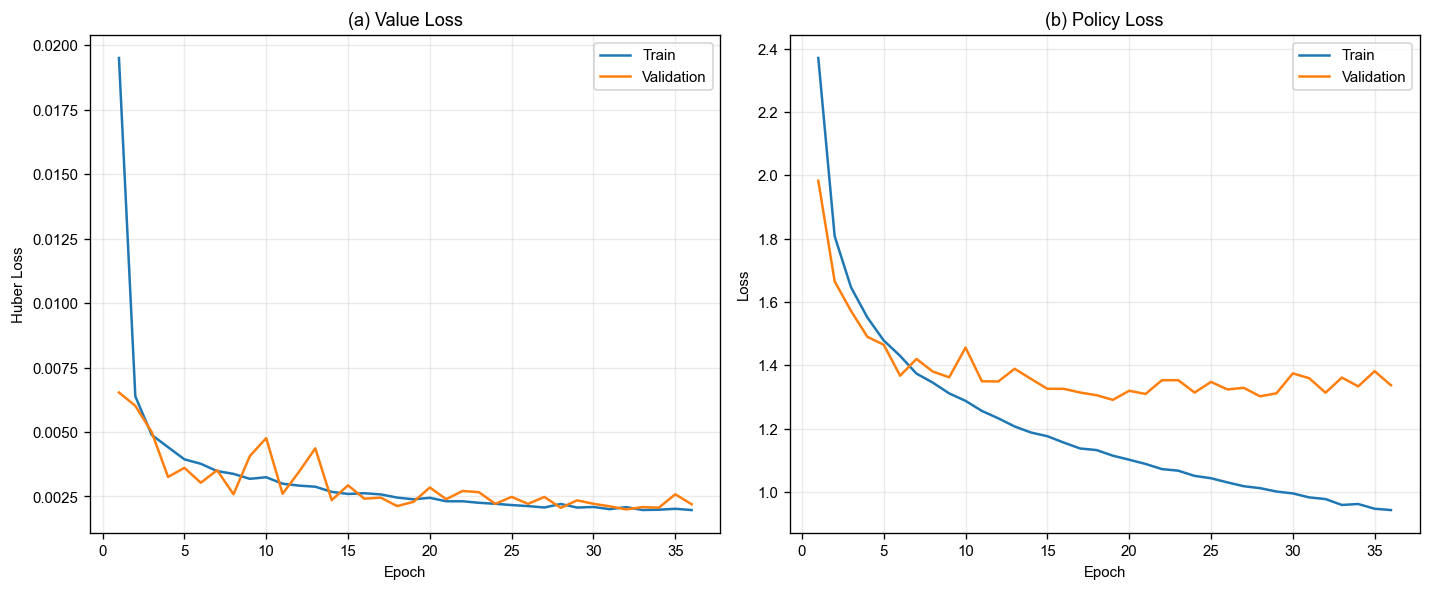

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]

ax.plot(history["epoch"], history["train_value"], label="Train")
ax.plot(history["epoch"], history["val_value"], label="Validation")

ax.set_title("(a) Value Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Huber Loss")
ax.legend()
ax.grid(alpha=0.25)


ax = axes[1]

ax.plot(history["epoch"], history["train_policy"], label="Train")
ax.plot(history["epoch"], history["val_policy"], label="Validation")

ax.set_title("(b) Policy Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend()
ax.grid(alpha=0.25)


plt.tight_layout()
plt.show()

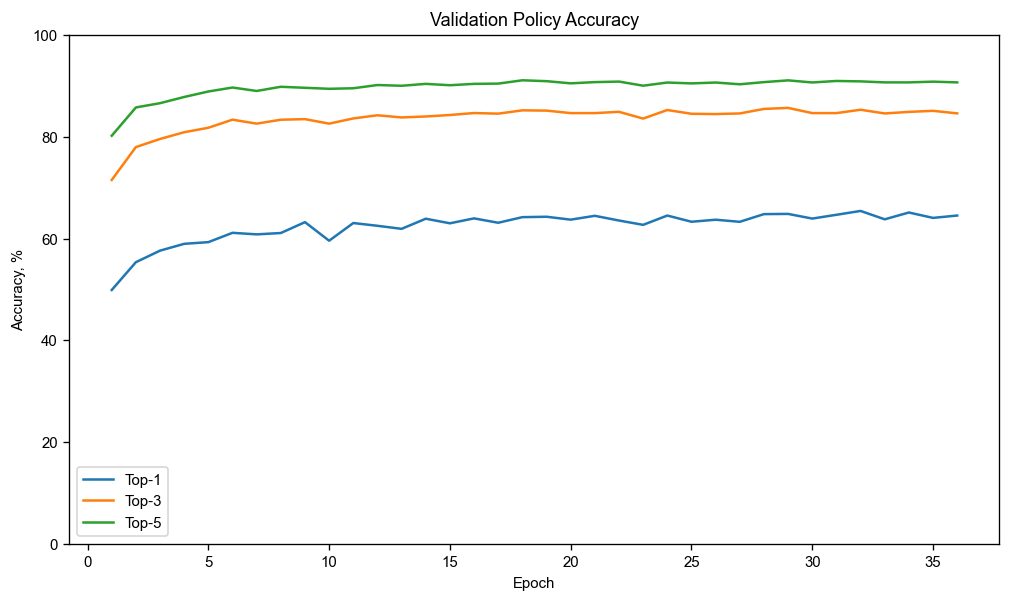

In [23]:
fig, ax = plt.subplots()

ax.plot(history["epoch"], 100 * history["val_top1"], label="Top-1")
ax.plot(history["epoch"], 100 * history["val_top3"], label="Top-3")
ax.plot(history["epoch"], 100 * history["val_top5"], label="Top-5")

ax.set_title("Validation Policy Accuracy")
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy, %")
ax.set_ylim(0, 100)
ax.legend()

plt.show()

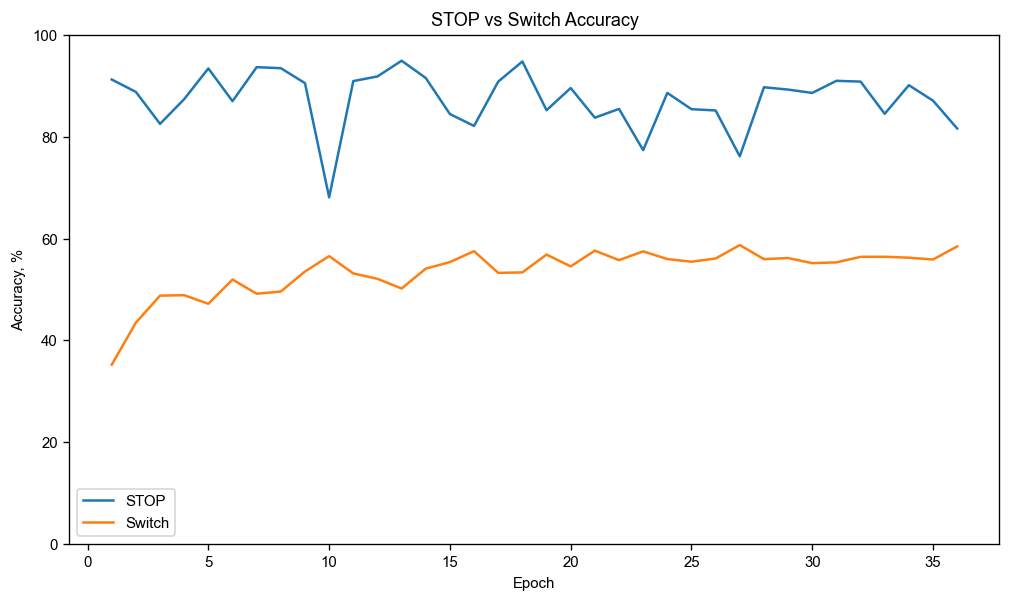

In [24]:
fig, ax = plt.subplots()

ax.plot(history["epoch"], 100 * history["val_stop"], label="STOP")
ax.plot(history["epoch"], 100 * history["val_switch"], label="Switch")

ax.set_title("STOP vs Switch Accuracy")
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy, %")
ax.set_ylim(0, 100)
ax.legend()

plt.show()

## 5. Runtime

Для validation inference используем тот же `NeuralPolicyValueEvaluator`,
что используется внутри MCTS.

In [25]:
evaluator = NeuralPolicyValueEvaluator(
    checkpoint_path=CHECKPOINT,
    device=DEVICE,
    enable_cache=True,
)

physics = evaluator.physics_config
topology_config = evaluator.topology_action_config

adapter = GridFMAdapter(
    RAW_DIR,
    physics_config=physics,
)

backend = GridFMPowerFlowBackend(
    adapter=adapter,
    physics_config=physics,
    enable_cache=True,
)

action_space = GridFMActionSpace(
    require_connected_after_switch=(
        topology_config.require_connected_after_switch
    ),
    min_loading_for_switch_percent=(
        topology_config.min_loading_for_switch_percent
    ),
    closeable_branch_ids=topology_config.closeable_branch_ids,
    enable_cache=True,
)

reward_fn = GridFMReward(
    physics_config=physics,
    discount_factor=1.0,
)

planner = MCTSPlanner(
    config=MCTSConfig(
        num_simulations=SIMULATIONS,
        max_depth=DEPTH,
        top_k_actions=TOP_K,
        widening_coefficient=WIDENING_COEFFICIENT,
        widening_exponent=WIDENING_EXPONENT,
        exploration_quota=EXPLORATION_QUOTA,
        gamma=1.0,
        c_puct=C_PUCT,
        fpu_value=FPU_VALUE,
        prior_exponent=PRIOR_EXPONENT,
        stop_policy=STOP_POLICY,
        include_stop_action=True,
        use_root_dirichlet_noise=False,
        random_seed=RANDOM_SEED,
    ),
    evaluator=evaluator,
    physics_config=physics,
)

loading_idx = BRANCH_FEATURE_COLUMNS.index("loading_percent")

In [26]:
def new_env(scenario_id):
    env = TopologySwitchingEnv(
        adapter=adapter,
        backend=backend,
        action_space=action_space,
        reward_fn=reward_fn,
        max_steps=MAX_STEPS,
        allow_handoff_with_hard_overloads=False,
    )
    env.reset(int(scenario_id))
    return env


def action_label(action):
    if action.action_id == 0:
        return "STOP / handoff"

    command = "OPEN" if action.target_status == 0 else "CLOSE"
    return f"{command} branch {action.branch_id}"

## 6. Policy + Value на всём validation set

Здесь Teacher states восстанавливаются replay-ем `selected_action_id`.
NPZ state-файлы не используются.

In [27]:
prediction_rows = []

started = time.perf_counter()

for scenario_id, episode in val_examples.groupby("scenario_id", sort=True):
    env = new_env(int(scenario_id))
    episode = episode.sort_values("step")

    for row in episode.itertuples():
        state = env.current_state
        action_mask = env.operational_action_mask()

        policy, predicted_value = evaluator.evaluate(
            state,
            action_mask,
        )

        target_policy = {
            int(action_id): float(probability)
            for action_id, probability in json.loads(row.mcts_policy_json).items()
        }

        teacher_action = max(
            target_policy,
            key=target_policy.get,
        )

        ranking = np.argsort(policy)[::-1]
        teacher_rank = int(
            np.where(ranking == teacher_action)[0][0]
        ) + 1

        prediction_rows.append(
            {
                "scenario_id": int(scenario_id),
                "difficulty_class": row.difficulty_class,
                "step": int(row.step),
                "teacher_action_id": int(teacher_action),
                "selected_action_id": int(row.selected_action_id),
                "predicted_action_id": int(np.argmax(policy)),
                "teacher_action_rank": teacher_rank,
                "target_value": float(row.outcome_value_target),
                "predicted_value": float(predicted_value),
            }
        )

        selected_action_id = int(row.selected_action_id)

        if selected_action_id == 0:
            break

        step_result = env.step(
            env.action_by_id(selected_action_id)
        )

        if step_result.done:
            break

predictions = pd.DataFrame(prediction_rows)

print(
    f"Replayed {predictions['scenario_id'].nunique():,} scenarios "
    f"and {len(predictions):,} states in "
    f"{time.perf_counter() - started:.1f} s"
)

display(predictions.head(15))

Replayed 2,000 scenarios and 6,966 states in 278.3 s


,scenario_id,difficulty_class,step,teacher_action_id,selected_action_id,predicted_action_id,teacher_action_rank,target_value,predicted_value
0,2,simple,0,165,165,166,3,0.980198,0.962669
1,2,simple,1,166,166,166,1,0.980198,0.975797
2,2,simple,2,0,0,0,1,0.980198,0.965373
3,12,simple,0,150,150,150,1,0.978796,0.967858
4,12,simple,1,147,147,147,1,0.978796,0.970267
5,12,simple,2,0,0,0,1,0.978796,0.980442
6,14,simple,0,166,166,166,1,0.992032,0.977693
7,14,simple,1,165,165,165,1,0.992032,0.969525
8,14,simple,2,0,0,0,1,0.992032,0.966590
9,19,simple,0,66,66,67,2,0.984127,0.957755


## 7. Value Head

In [28]:
def value_metrics(df):
    target = df["target_value"].to_numpy(float)
    pred = df["predicted_value"].to_numpy(float)
    error = pred - target

    target_rank = pd.Series(target).rank()
    pred_rank = pd.Series(pred).rank()

    sse = np.sum(error ** 2)
    sst = np.sum((target - target.mean()) ** 2)

    return pd.Series(
        {
            "N": len(df),
            "MAE": np.mean(np.abs(error)),
            "RMSE": np.sqrt(np.mean(error ** 2)),
            "R2": 1.0 - sse / sst,
            "Pearson": np.corrcoef(target, pred)[0, 1],
            "Spearman": target_rank.corr(pred_rank),
            "Target std": target.std(),
            "Prediction std": pred.std(),
            "Bias": error.mean(),
        }
    )


value_summary = pd.concat(
    [
        value_metrics(predictions).rename("all"),
        *[
            value_metrics(
                predictions[
                    predictions["difficulty_class"] == difficulty
                ]
            ).rename(difficulty)
            for difficulty in DIFFICULTIES
        ],
    ],
    axis=1,
).T

display(value_summary.round(4))

,N,MAE,RMSE,R2,Pearson,Spearman,Target std,Prediction std,Bias
all,6966.0,0.0463,0.0668,0.9761,0.9887,0.9390,0.4327,0.4213,0.0148
simple,1411.0,0.0266,0.0345,0.5463,0.7468,0.6414,0.0512,0.0359,0.0049
medium,3605.0,0.0419,0.0592,0.9013,0.9522,0.8800,0.1884,0.1822,0.0136
hard,1950.0,0.0688,0.0928,0.9522,0.9776,0.9773,0.4247,0.4077,0.0243


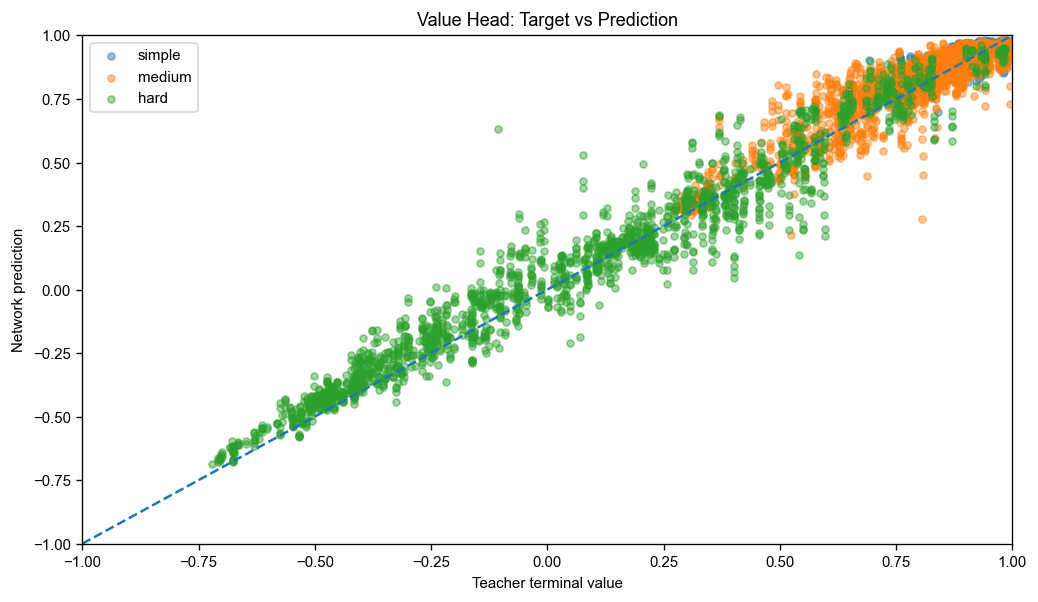

In [29]:
fig, ax = plt.subplots()

for difficulty in DIFFICULTIES:
    data = predictions[
        predictions["difficulty_class"] == difficulty
    ]

    ax.scatter(
        data["target_value"],
        data["predicted_value"],
        s=18,
        alpha=0.45,
        label=difficulty,
    )

ax.plot([-1, 1], [-1, 1], linestyle="--")

ax.set_title("Value Head: Target vs Prediction")
ax.set_xlabel("Teacher terminal value")
ax.set_ylabel("Network prediction")
ax.set_xlim(-1, 1)
ax.set_ylim(-1, 1)
ax.legend()

plt.show()

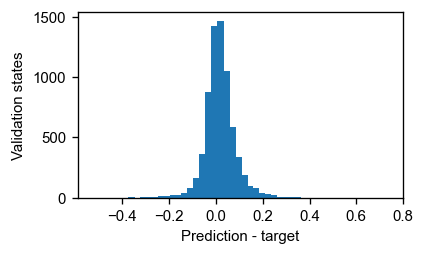

In [71]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 9

fig, ax = plt.subplots(figsize=(3.35, 2.0))

error = predictions["predicted_value"] - predictions["target_value"]

# Calculate histogram
counts, edges = np.histogram(error, bins=50)

# Histogram as a single vector object
ax.stairs(
    counts,
    edges,
    fill=True,
    facecolor="#1f77b4",
    edgecolor="#1f77b4",
    linewidth=0.4,
    antialiased=False,
    zorder=2
)

ax.set_ylim(bottom=0)

ax.set_xlabel("Prediction - target", fontsize=9)
ax.set_ylabel("Validation states", fontsize=9)
ax.tick_params(axis="both", labelsize=9)

plt.tight_layout(pad=0.25)

plt.savefig(
    "value_prediction_error.svg",
    bbox_inches="tight"
)

plt.show()

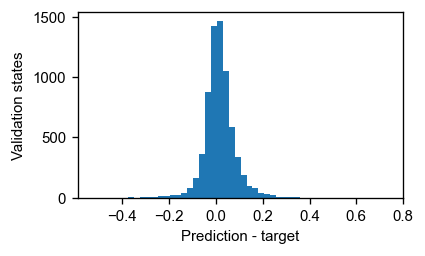

In [70]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 9

fig, ax = plt.subplots(figsize=(3.35, 2.0))

error = predictions["predicted_value"] - predictions["target_value"]
error = np.asarray(error)

# Histogram from scratch
counts, edges = np.histogram(error, bins=50)
widths = np.diff(edges)

ax.bar(
    edges[:-1],
    counts,
    width=widths,
    align="edge",
    color="#1f77b4",
    edgecolor="#1f77b4",
    linewidth=0
)

# Zero reference line

ax.set_ylim(bottom=0)

ax.set_xlabel("Prediction - target", fontsize=9)
ax.set_ylabel("Validation states", fontsize=9)
ax.tick_params(axis="both", labelsize=9)

plt.tight_layout(pad=0.25)

plt.savefig(
    "figures/value_prediction_error.svg",
    bbox_inches="tight"
)

plt.show()

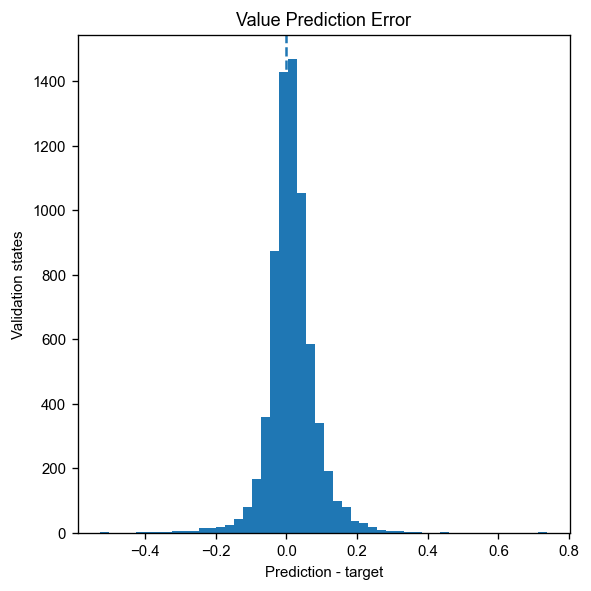

In [31]:
fig, ax = plt.subplots(figsize=(5, 5))

error = predictions["predicted_value"] - predictions["target_value"]

ax.hist(error, bins=50)
ax.axvline(0, linestyle="--")

ax.set_title("Value Prediction Error")
ax.set_xlabel("Prediction - target")
ax.set_ylabel("Validation states")

plt.tight_layout()
plt.show()

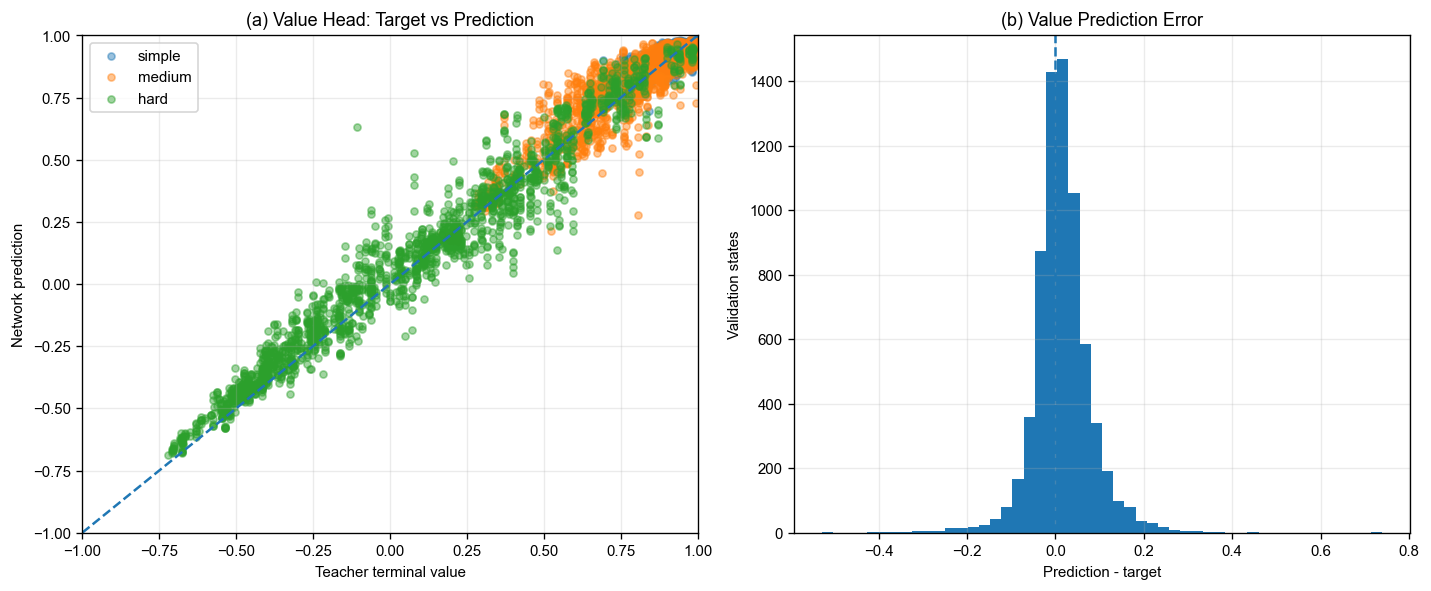

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]

for difficulty in DIFFICULTIES:
    data = predictions[
        predictions["difficulty_class"] == difficulty
    ]

    ax.scatter(
        data["target_value"],
        data["predicted_value"],
        s=18,
        alpha=0.45,
        label=difficulty,
    )

ax.plot([-1, 1], [-1, 1], linestyle="--")

ax.set_title("(a) Value Head: Target vs Prediction")
ax.set_xlabel("Teacher terminal value")
ax.set_ylabel("Network prediction")
ax.set_xlim(-1, 1)
ax.set_ylim(-1, 1)
ax.legend()
ax.grid(alpha=0.25)


ax = axes[1]

error = predictions["predicted_value"] - predictions["target_value"]

ax.hist(error, bins=50)
ax.axvline(0, linestyle="--")

ax.set_title("(b) Value Prediction Error")
ax.set_xlabel("Prediction - target")
ax.set_ylabel("Validation states")
ax.grid(alpha=0.25)


plt.tight_layout()
plt.show()

## 8. Policy Head

In [33]:
def policy_metrics(df):
    rank = df["teacher_action_rank"].to_numpy(int)

    stop = df["teacher_action_id"] == 0
    switch = df["teacher_action_id"] != 0

    stop_accuracy = np.mean(
        df.loc[stop, "predicted_action_id"]
        == df.loc[stop, "teacher_action_id"]
    )

    switch_accuracy = np.mean(
        df.loc[switch, "predicted_action_id"]
        == df.loc[switch, "teacher_action_id"]
    )

    return pd.Series(
        {
            "N": len(df),
            "Top-1, %": 100 * np.mean(rank <= 1),
            "Top-3, %": 100 * np.mean(rank <= 3),
            "Top-5, %": 100 * np.mean(rank <= 5),
            "STOP accuracy, %": 100 * stop_accuracy,
            "Switch exact, %": 100 * switch_accuracy,
            "Mean teacher rank": rank.mean(),
            "Median teacher rank": np.median(rank),
        }
    )


policy_summary = pd.concat(
    [
        policy_metrics(predictions).rename("all"),
        *[
            policy_metrics(
                predictions[
                    predictions["difficulty_class"] == difficulty
                ]
            ).rename(difficulty)
            for difficulty in DIFFICULTIES
        ],
    ],
    axis=1,
).T

display(policy_summary.round(2))

,N,"Top-1, %","Top-3, %","Top-5, %","STOP accuracy, %","Switch exact, %",Mean teacher rank,Median teacher rank
all,6966.0,63.74,84.71,90.67,85.94,57.38,3.13,1.0
simple,1411.0,69.88,88.80,93.27,92.17,57.72,2.42,1.0
medium,3605.0,66.05,85.55,90.98,86.16,60.56,3.09,1.0
hard,1950.0,55.03,80.21,88.21,74.29,51.80,3.72,1.0


,Top1,Top3,Top5
difficulty_class,,,
simple,69.88,88.80,93.27
medium,66.05,85.55,90.98
hard,55.03,80.21,88.21


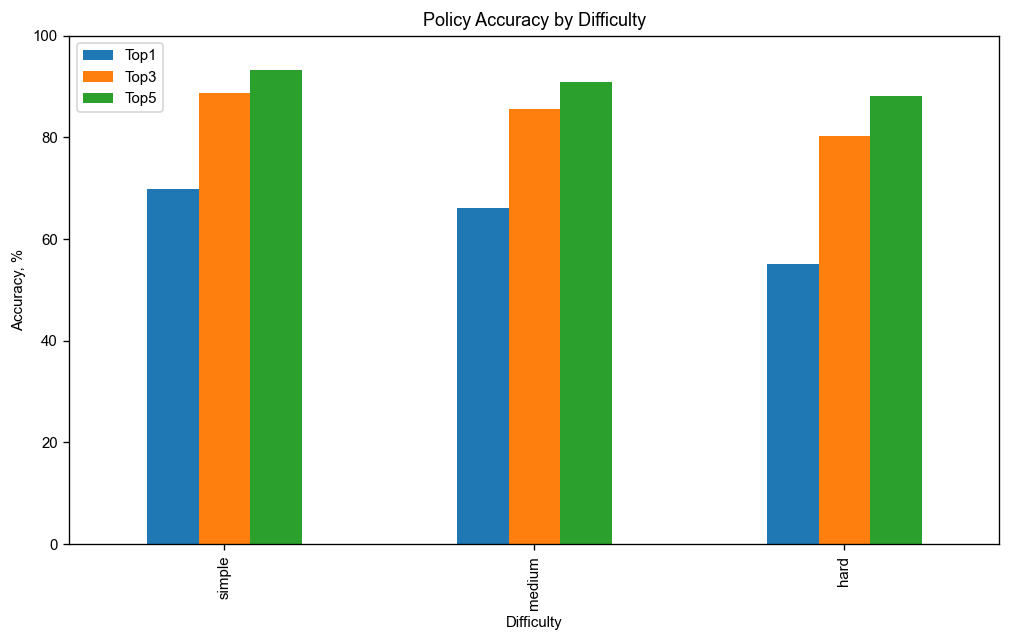

In [34]:
topk = (
    predictions
    .groupby("difficulty_class")["teacher_action_rank"]
    .agg(
        Top1=lambda x: 100 * np.mean(x <= 1),
        Top3=lambda x: 100 * np.mean(x <= 3),
        Top5=lambda x: 100 * np.mean(x <= 5),
    )
    .reindex(DIFFICULTIES)
)

display(topk.round(2))

fig, ax = plt.subplots()

topk.plot(kind="bar", ax=ax)

ax.set_title("Policy Accuracy by Difficulty")
ax.set_xlabel("Difficulty")
ax.set_ylabel("Accuracy, %")
ax.set_ylim(0, 100)

plt.show()

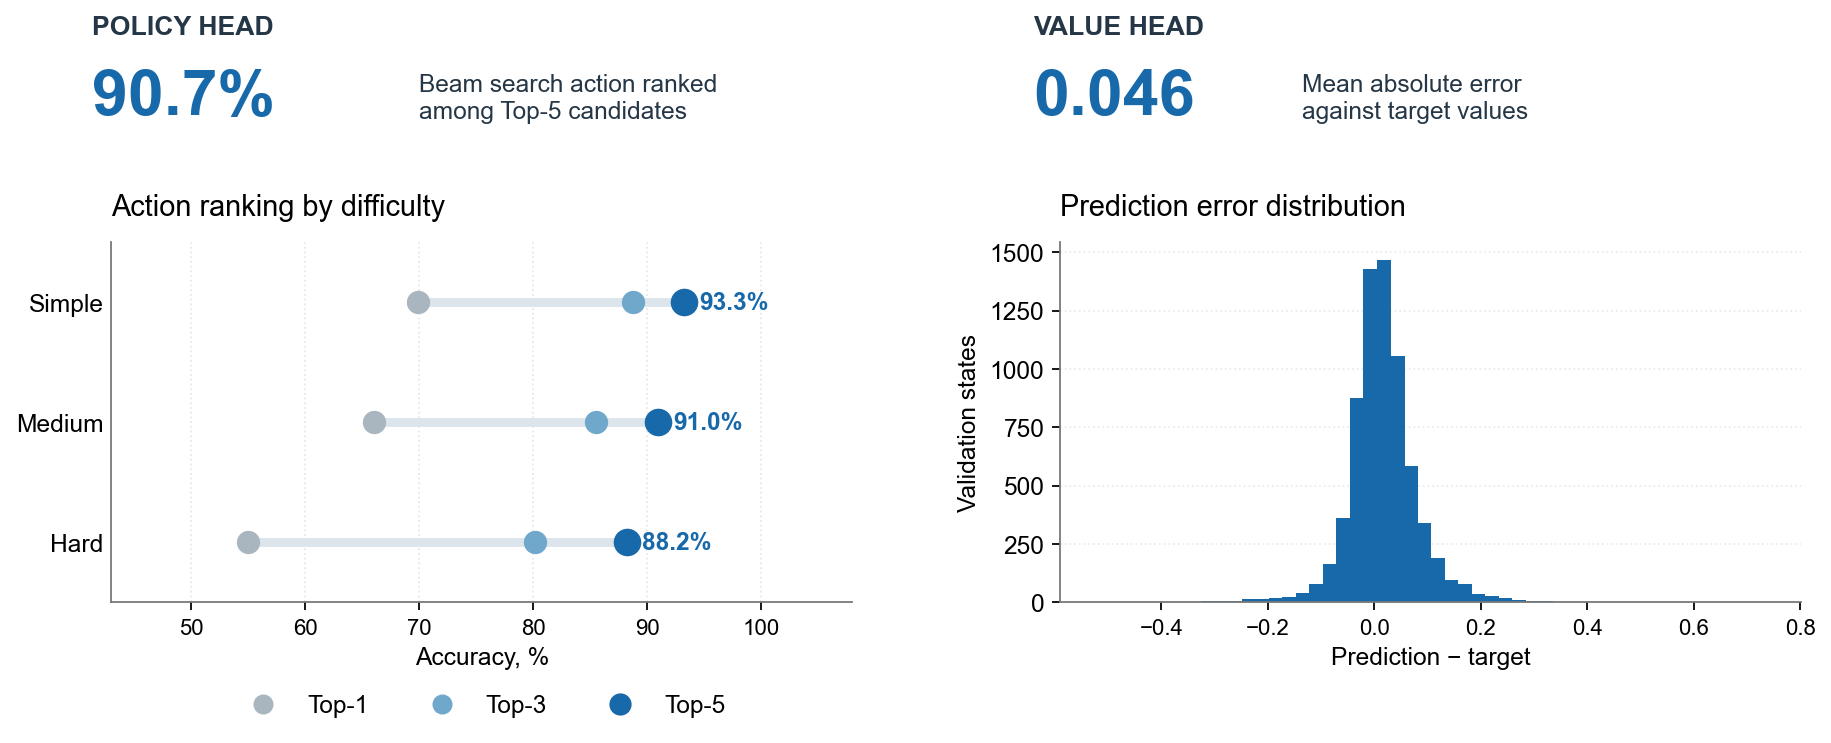

In [72]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path

# ------------------------------------------------------------
# Data
# ------------------------------------------------------------

topk = (
    predictions
    .groupby("difficulty_class")["teacher_action_rank"]
    .agg(
        Top1=lambda x: 100 * np.mean(x <= 1),
        Top3=lambda x: 100 * np.mean(x <= 3),
        Top5=lambda x: 100 * np.mean(x <= 5),
    )
    .reindex(DIFFICULTIES)
)

error = (
    predictions["predicted_value"]
    - predictions["target_value"]
).to_numpy()

error = error[np.isfinite(error)]

overall_top5 = 100 * np.mean(
    predictions["teacher_action_rank"] <= 5
)

mae = np.mean(np.abs(error))


# ------------------------------------------------------------
# Style
# ------------------------------------------------------------

blue = "#1769AA"
medium_blue = "#70A8CB"
gray = "#A9B5BF"
light_gray = "#DCE5EC"
dark = "#253746"

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 11,
    "svg.fonttype": "none",
})

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(12, 5),
    dpi=160,
    gridspec_kw={"width_ratios": [1, 1]}
)


# ------------------------------------------------------------
# Main numbers
# ------------------------------------------------------------

fig.text(
    0.08, 0.94,
    "POLICY HEAD",
    fontsize=12,
    fontweight="bold",
    color=dark
)

fig.text(
    0.08, 0.84,
    f"{overall_top5:.1f}%",
    fontsize=29,
    fontweight="bold",
    color=blue
)

fig.text(
    0.25, 0.86,
    "Beam search action ranked\namong Top-5 candidates",
    fontsize=11,
    color=dark,
    va="center"
)

fig.text(
    0.57, 0.94,
    "VALUE HEAD",
    fontsize=12,
    fontweight="bold",
    color=dark
)

fig.text(
    0.57, 0.84,
    f"{mae:.3f}",
    fontsize=29,
    fontweight="bold",
    color=blue
)

fig.text(
    0.71, 0.86,
    "Mean absolute error\nagainst target values",
    fontsize=11,
    color=dark,
    va="center"
)


# ------------------------------------------------------------
# Left: Policy accuracy
# ------------------------------------------------------------

y = np.arange(len(topk))[::-1]

for i, difficulty in enumerate(topk.index):

    top1 = topk.loc[difficulty, "Top1"]
    top3 = topk.loc[difficulty, "Top3"]
    top5 = topk.loc[difficulty, "Top5"]

    # Connection between Top-1 and Top-5
    ax1.plot(
        [top1, top5],
        [y[i], y[i]],
        color=light_gray,
        linewidth=4,
        solid_capstyle="round",
        zorder=1
    )

    # Top-1
    ax1.scatter(
        top1, y[i],
        color=gray,
        s=90,
        zorder=3
    )

    # Top-3
    ax1.scatter(
        top3, y[i],
        color=medium_blue,
        s=90,
        zorder=3
    )

    # Top-5
    ax1.scatter(
        top5, y[i],
        color=blue,
        s=130,
        zorder=4
    )

    # Top-5 numerical label
    ax1.text(
        top5 + 1.3,
        y[i],
        f"{top5:.1f}%",
        va="center",
        ha="left",
        fontsize=11,
        color=blue,
        fontweight="bold"
    )


ax1.set_yticks(y)
ax1.set_yticklabels(
    [str(d).capitalize() for d in topk.index]
)

ax1.set_xlim(
    max(0, topk.min().min() - 12),
    108
)

ax1.set_ylim(-0.5, len(y) - 0.5)

ax1.set_xlabel("Accuracy, %")

ax1.set_title(
    "Action ranking by difficulty",
    loc="left",
    pad=12
)

ax1.grid(
    axis="x",
    linestyle=":",
    alpha=0.3
)

ax1.tick_params(axis="y", length=0)


# ------------------------------------------------------------
# Right: Value prediction error
# ------------------------------------------------------------

counts, edges = np.histogram(error, bins=50)

ax2.stairs(
    counts,
    edges,
    fill=True,
    facecolor=blue,
    edgecolor=blue,
    linewidth=0.4,
    antialiased=False
)

ax2.set_ylim(bottom=0)

ax2.set_xlabel("Prediction − target")
ax2.set_ylabel("Validation states")

ax2.set_title(
    "Prediction error distribution",
    loc="left",
    pad=12
)

ax2.grid(
    axis="y",
    linestyle=":",
    alpha=0.25
)


# ------------------------------------------------------------
# Clean axes
# ------------------------------------------------------------

for ax in (ax1, ax2):
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_color("#777777")
    ax.spines["bottom"].set_color("#777777")


# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor=gray,
        markeredgecolor=gray,
        markersize=8,
        label="Top-1"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor=medium_blue,
        markeredgecolor=medium_blue,
        markersize=8,
        label="Top-3"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor=blue,
        markeredgecolor=blue,
        markersize=9,
        label="Top-5"
    ),
]

ax1.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.38),
    ncol=3,
    frameon=False,
    fontsize=11
)


# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

plt.subplots_adjust(
    left=0.09,
    right=0.97,
    top=0.68,
    bottom=0.23,
    wspace=0.28
)


# ------------------------------------------------------------
# Save to figures/
# ------------------------------------------------------------

output_dir = Path("figures")
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "gnn_validation_slide.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    output_dir / "gnn_validation_slide.svg",
    bbox_inches="tight"
)

plt.show()

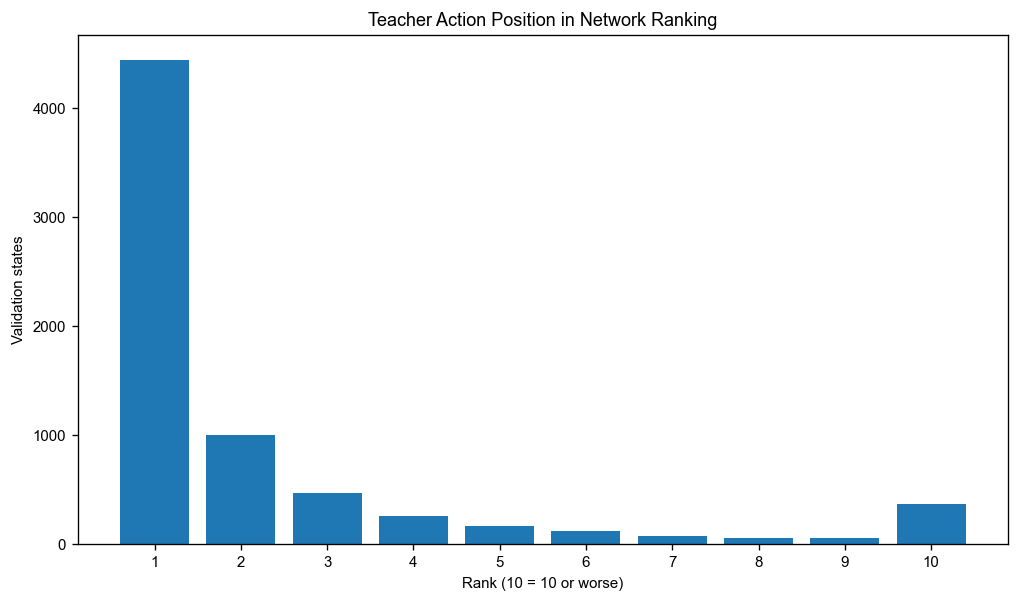

In [35]:
rank_distribution = (
    predictions["teacher_action_rank"]
    .clip(upper=10)
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots()

ax.bar(
    rank_distribution.index.astype(str),
    rank_distribution.values,
)

ax.set_title("Teacher Action Position in Network Ranking")
ax.set_xlabel("Rank (10 = 10 or worse)")
ax.set_ylabel("Validation states")

plt.show()

,Top1,Top3,Top5
difficulty_class,,,
simple,69.88,88.80,93.27
medium,66.05,85.55,90.98
hard,55.03,80.21,88.21


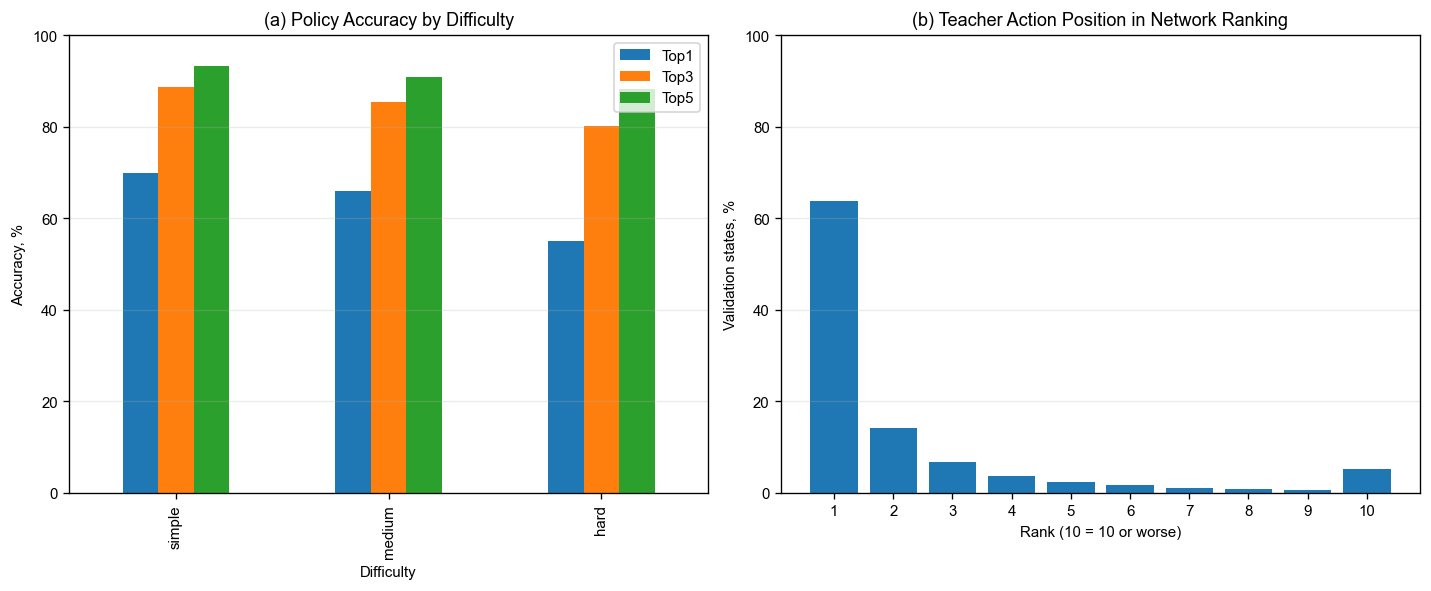

In [36]:
topk = (
    predictions
    .groupby("difficulty_class")["teacher_action_rank"]
    .agg(
        Top1=lambda x: 100 * np.mean(x <= 1),
        Top3=lambda x: 100 * np.mean(x <= 3),
        Top5=lambda x: 100 * np.mean(x <= 5),
    )
    .reindex(DIFFICULTIES)
)

display(topk.round(2))


rank_distribution = (
    predictions["teacher_action_rank"]
    .clip(upper=10)
    .value_counts()
    .sort_index()
)

rank_distribution_pct = (
    100 * rank_distribution / rank_distribution.sum()
)


fig, axes = plt.subplots(1, 2, figsize=(12, 5))


ax = axes[0]

topk.plot(kind="bar", ax=ax)

ax.set_title("(a) Policy Accuracy by Difficulty")
ax.set_xlabel("Difficulty")
ax.set_ylabel("Accuracy, %")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.25)


ax = axes[1]

ax.bar(
    rank_distribution_pct.index.astype(str),
    rank_distribution_pct.values,
)

ax.set_title("(b) Teacher Action Position in Network Ranking")
ax.set_xlabel("Rank (10 = 10 or worse)")
ax.set_ylabel("Validation states, %")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.25)


plt.tight_layout()
plt.show()

## 9. Подробно один scenario

In [37]:
env = new_env(SCENARIO_ID)
state = env.current_state

assessment = assess_physical_state(state.metrics)

state_summary = pd.DataFrame(
    {
        "value": [
            SCENARIO_ID,
            state_security_penalty(
                state,
                physics_config=physics,
            ),
            state.metrics["max_loading_percent"],
            state.metrics["num_overloaded_branches"],
            state.metrics["num_hard_overloaded_branches"],
            assessment.hard_overload_free,
            assessment.physically_secure,
        ]
    },
    index=[
        "scenario_id",
        "J",
        "max_loading_%",
        "overloaded_branches",
        "hard_overloaded_branches",
        "hard_overload_free",
        "physically_secure",
    ],
)

display(state_summary)

,value
scenario_id,12754
J,490.089203
max_loading_%,136.545095
overloaded_branches,3
hard_overloaded_branches,3
hard_overload_free,False
physically_secure,False


,value
Network,0.1041
Teacher,0.2392


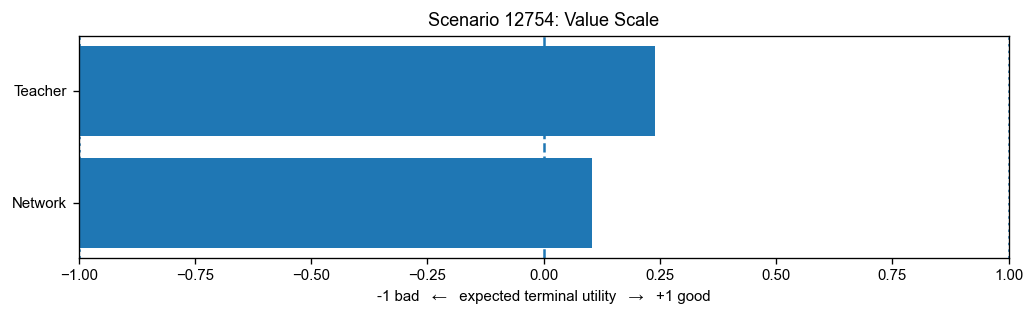

In [38]:
root_teacher = (
    val_examples[
        (val_examples["scenario_id"] == SCENARIO_ID)
        & (val_examples["step"] == 0)
    ]
    .iloc[0]
)

root_policy, root_value = evaluator.evaluate(
    env.current_state,
    env.operational_action_mask(),
)

teacher_value = float(
    root_teacher["outcome_value_target"]
)

value_bar = pd.DataFrame(
    {
        "value": [
            root_value,
            teacher_value,
        ]
    },
    index=[
        "Network",
        "Teacher",
    ],
)

display(value_bar.round(4))

fig, ax = plt.subplots(figsize=(10, 2.4))

ax.barh(
    value_bar.index,
    value_bar["value"] + 1.0,
    left=-1.0,
)

ax.axvline(-1, linestyle=":")
ax.axvline(0, linestyle="--")
ax.axvline(1, linestyle=":")

ax.set_xlim(-1, 1)
ax.set_title(f"Scenario {SCENARIO_ID}: Value Scale")
ax.set_xlabel("-1 bad   ←   expected terminal utility   →   +1 good")

plt.show()

## 10. Что предлагает сама сеть

In [39]:
network_rows = []

for action_id in np.argsort(root_policy)[::-1]:
    if root_policy[action_id] <= 0:
        continue

    action = env.action_by_id(int(action_id))

    loading = np.nan

    if action.branch_pos is not None:
        loading = float(
            state.branch_features[
                action.branch_pos,
                loading_idx,
            ]
        )

    network_rows.append(
        {
            "action_id": int(action_id),
            "action": action_label(action),
            "branch_id": action.branch_id,
            "branch_loading_%": loading,
            "probability_%": 100 * float(root_policy[action_id]),
        }
    )

network_actions = pd.DataFrame(network_rows).head(12)

network_actions["Teacher"] = (
    network_actions["action_id"]
    == int(root_teacher["selected_action_id"])
)

display(
    network_actions.style.format(
        {
            "branch_loading_%": "{:.2f}",
            "probability_%": "{:.2f}",
        }
    )
)

,action_id,action,branch_id,branch_loading_%,probability_%,Teacher
0,31,OPEN branch 30,30.000000,60.16,86.58,True
1,61,OPEN branch 60,60.000000,18.42,3.96,False
2,118,OPEN branch 117,117.000000,14.90,3.88,False
3,96,OPEN branch 95,95.000000,27.85,1.75,False
4,66,OPEN branch 65,65.000000,62.45,0.90,False
5,67,OPEN branch 66,66.000000,61.63,0.89,False
6,59,OPEN branch 58,58.000000,12.06,0.46,False
7,117,OPEN branch 116,116.000000,21.83,0.43,False
8,128,OPEN branch 127,127.000000,29.27,0.35,False
9,0,STOP / handoff,nan,nan,0.31,False


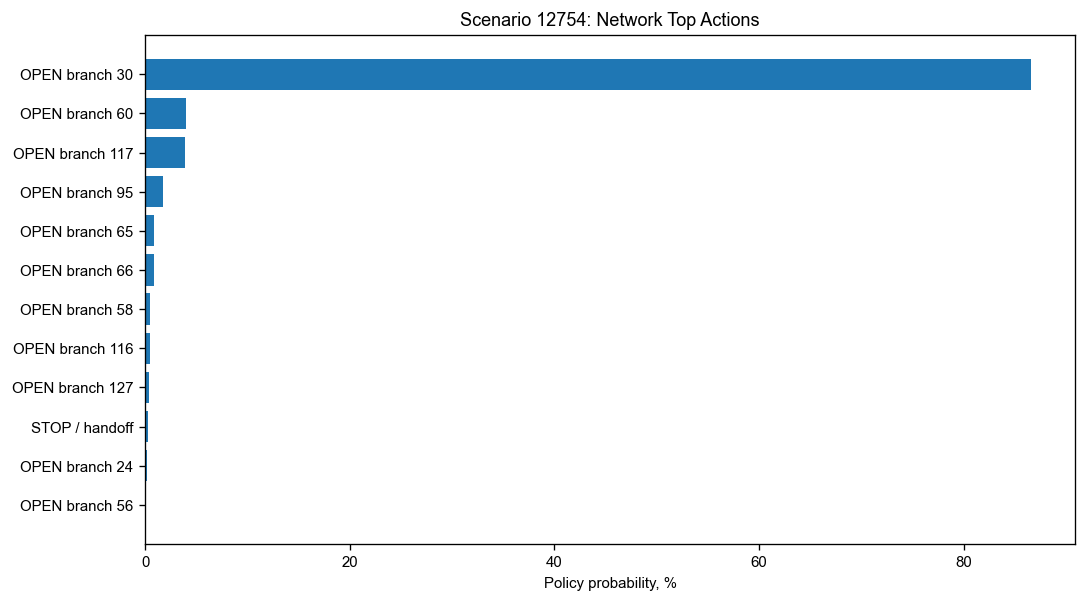

In [40]:
fig, ax = plt.subplots()

plot_data = network_actions.iloc[::-1]

ax.barh(
    plot_data["action"],
    plot_data["probability_%"],
)

ax.set_title(f"Scenario {SCENARIO_ID}: Network Top Actions")
ax.set_xlabel("Policy probability, %")

plt.show()

## 11. Что предлагает MCTS

In [41]:
planner.reset_rng(RANDOM_SEED)
search = planner.search_from_env(env)

total_visits = sum(search.visit_counts.values())

mcts_rows = []

for action_id, visits in sorted(
    search.visit_counts.items(),
    key=lambda item: item[1],
    reverse=True,
):
    action = search.root.actions_by_id[int(action_id)]
    child = search.root.children[int(action_id)]

    mcts_rows.append(
        {
            "action_id": int(action_id),
            "action": action_label(action),
            "branch_id": action.branch_id,
            "visits": int(visits),
            "visit_share_%": 100 * visits / total_visits,
            "Q": child.mean_value,
            "prior": search.root.action_priors.get(
                int(action_id),
                np.nan,
            ),
        }
    )

mcts_actions = pd.DataFrame(mcts_rows).head(12)

mcts_actions["Teacher"] = (
    mcts_actions["action_id"]
    == int(root_teacher["selected_action_id"])
)

display(
    mcts_actions.style.format(
        {
            "visit_share_%": "{:.2f}",
            "Q": "{:+.3f}",
            "prior": "{:.4f}",
        }
    )
)

print("Selected action:", search.best_action_id)
print("Selected branch:", search.best_branch_id)
print(
    "Visited action coverage:",
    f"{100 * search.root_visited_action_coverage:.2f}%",
)

,action_id,action,branch_id,visits,visit_share_%,Q,prior,Teacher
0,31,OPEN branch 30,30,142,94.67,+0.274,0.8686,True
1,61,OPEN branch 60,60,3,2.00,+0.105,0.0397,False
2,118,OPEN branch 117,117,3,2.00,+0.157,0.0390,False
3,101,OPEN branch 100,100,1,0.67,+0.103,0.0000,False
4,92,OPEN branch 91,91,1,0.67,+0.103,0.0000,False


Selected action: 31
Selected branch: 30
Visited action coverage: 2.84%


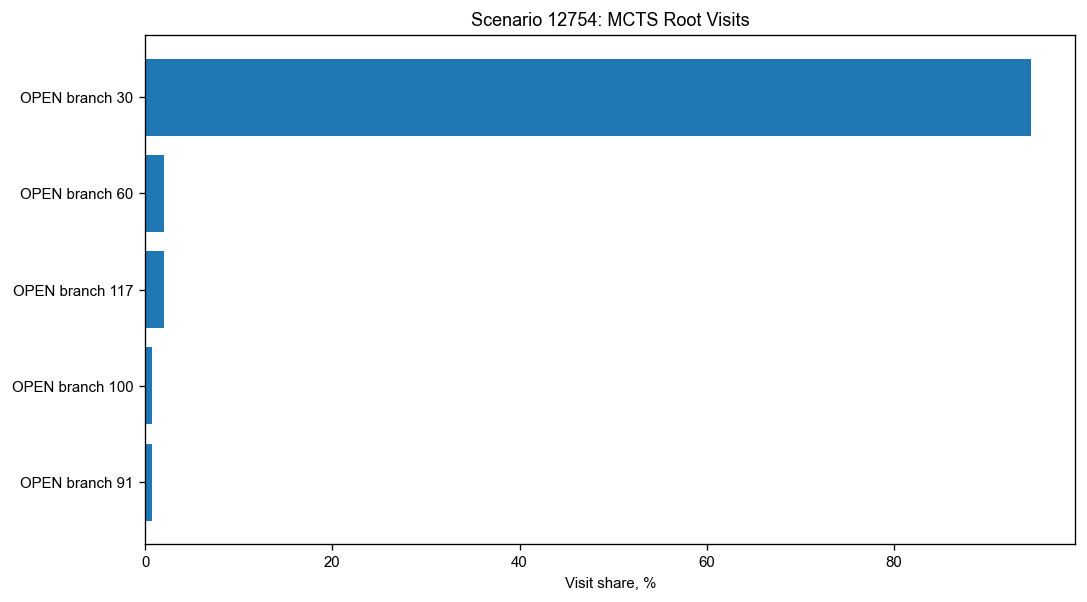

In [42]:
fig, ax = plt.subplots()

plot_data = mcts_actions.iloc[::-1]

ax.barh(
    plot_data["action"],
    plot_data["visit_share_%"],
)

ax.set_title(f"Scenario {SCENARIO_ID}: MCTS Root Visits")
ax.set_xlabel("Visit share, %")

plt.show()

## 12. IEEE-118 topology и Top-5 предложенных ветвей

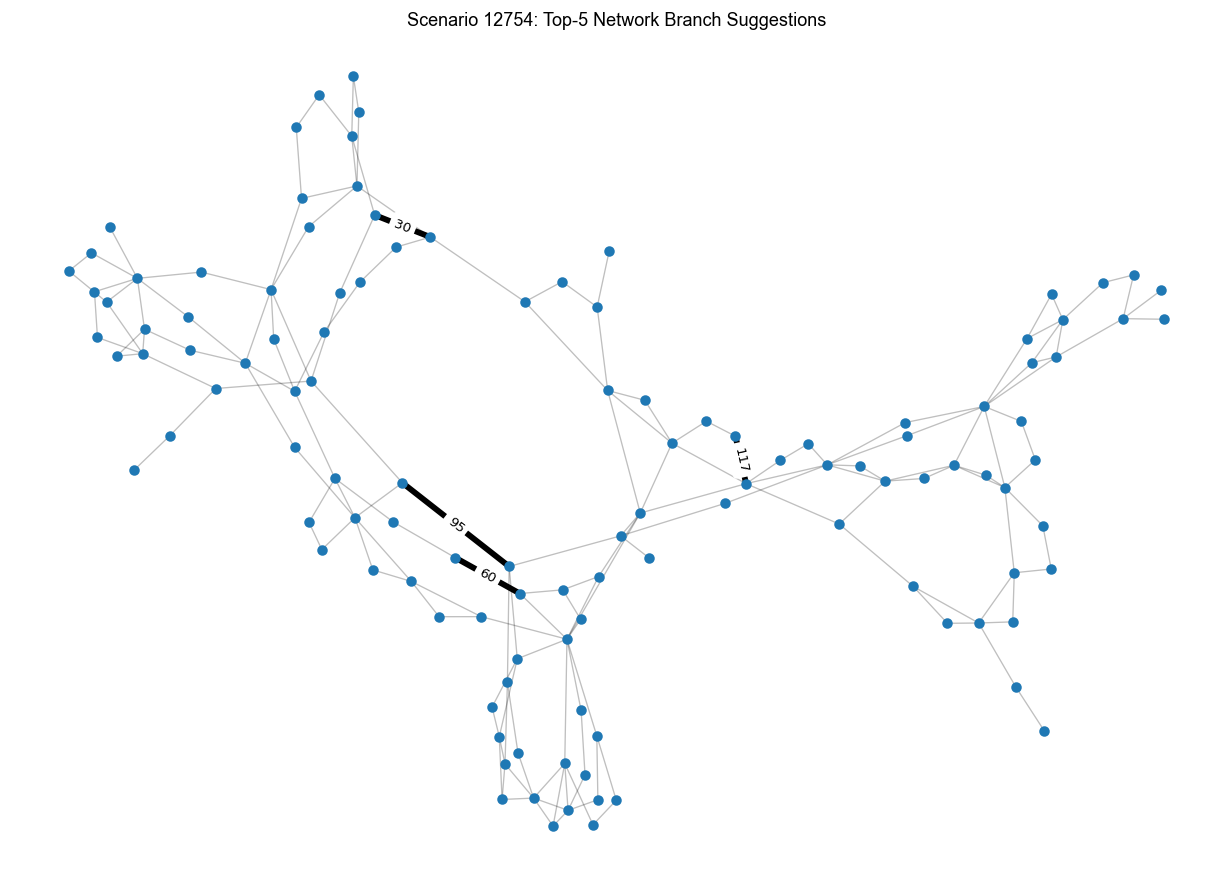

In [43]:
bus_ids = np.asarray(state.bus_ids, dtype=int)
branch_ids = np.asarray(state.branch_ids, dtype=int)
edge_index = np.asarray(state.edge_index, dtype=int)

from_bus = bus_ids[edge_index[0]]
to_bus = bus_ids[edge_index[1]]

top_branches = set(
    network_actions["branch_id"]
    .dropna()
    .head(5)
    .astype(int)
)

graph = nx.Graph()

for branch_id, left, right in zip(
    branch_ids,
    from_bus,
    to_bus,
):
    graph.add_edge(
        int(left),
        int(right),
        branch_id=int(branch_id),
    )

pos = nx.spring_layout(
    graph,
    seed=42,
    iterations=400,
)

widths = []
alphas = []

for left, right, data in graph.edges(data=True):
    if data["branch_id"] in top_branches:
        widths.append(3.5)
        alphas.append(1.0)
    else:
        widths.append(0.8)
        alphas.append(0.25)

fig, ax = plt.subplots(figsize=(13, 9))

nx.draw_networkx_nodes(
    graph,
    pos,
    node_size=28,
    ax=ax,
)

for (left, right, data), width, alpha in zip(
    graph.edges(data=True),
    widths,
    alphas,
):
    nx.draw_networkx_edges(
        graph,
        pos,
        edgelist=[(left, right)],
        width=width,
        alpha=alpha,
        ax=ax,
    )

labels = {
    (left, right): str(data["branch_id"])
    for left, right, data in graph.edges(data=True)
    if data["branch_id"] in top_branches
}

nx.draw_networkx_edge_labels(
    graph,
    pos,
    edge_labels=labels,
    font_size=8,
    ax=ax,
)

ax.set_title(
    f"Scenario {SCENARIO_ID}: Top-5 Network Branch Suggestions"
)
ax.axis("off")

plt.show()

## 13. Полный MCTS rollout

In [44]:
def run_mcts_episode(scenario_id):
    env = new_env(scenario_id)

    trace = []

    initial_J = state_security_penalty(
        env.current_state,
        physics_config=physics,
    )

    for step in range(MAX_STEPS):
        if env.done:
            break

        current = env.current_state

        _, predicted_value = evaluator.evaluate(
            current,
            env.operational_action_mask(),
        )

        planner.reset_rng(
            RANDOM_SEED + step
        )

        result = planner.search_from_env(
            env
        )

        if not result.policy:
            break

        policy = normalize_policy(
            result.policy,
            context="notebook evaluation policy",
        )

        action_id = select_action_from_policy(
            policy,
            temperature=0.0,
            rng=np.random.default_rng(0),
            context="notebook evaluation policy",
        )

        action = (
            make_do_nothing_action()
            if action_id == 0
            else result.root.actions_by_id[action_id]
        )

        J_before = state_security_penalty(
            current,
            physics_config=physics,
        )

        step_result = env.step(action)

        J_after = state_security_penalty(
            env.current_state,
            physics_config=physics,
        )

        trace.append(
            {
                "step": step,
                "predicted_value": predicted_value,
                "action_id": int(action_id),
                "action": action_label(action),
                "branch_id": action.branch_id,
                "MCTS_visit_share_%": 100 * result.policy[action_id],
                "J_before": J_before,
                "J_after": J_after,
                "delta_J": J_before - J_after,
                "max_loading_%": float(
                    env.current_state.metrics[
                        "max_loading_percent"
                    ]
                ),
                "visited_coverage_%": (
                    100 * result.root_visited_action_coverage
                ),
            }
        )

        if step_result.done:
            break

    final_state = env.current_state
    final_assessment = assess_physical_state(
        final_state.metrics
    )

    if final_assessment.physically_secure:
        redispatch_validated = True
        redispatch_l1_mw = 0.0
    else:
        redispatch = run_minimal_ac_redispatch(
            backend,
            final_state,
        )

        redispatch_validated = redispatch.validated
        redispatch_l1_mw = redispatch.redispatch_l1_mw

    final_J = state_security_penalty(
        final_state,
        physics_config=physics,
    )

    summary = {
        "scenario_id": int(scenario_id),
        "J0": initial_J,
        "Jfinal": final_J,
        "delta_J": initial_J - final_J,
        "steps": len(trace),
        "switches": sum(
            item["branch_id"] is not None
            for item in trace
        ),
        "topology_secure": final_assessment.physically_secure,
        "hard_overload_free": final_assessment.hard_overload_free,
        "redispatch_validated": bool(redispatch_validated),
        "redispatch_l1_mw": redispatch_l1_mw,
        "terminal_validated": bool(
            final_assessment.physically_secure
            or redispatch_validated
        ),
        "final_max_loading_%": float(
            final_state.metrics[
                "max_loading_percent"
            ]
        ),
        "final_hard_overloads": int(
            final_state.metrics[
                "num_hard_overloaded_branches"
            ]
        ),
    }

    return summary, pd.DataFrame(trace)

In [45]:
scenario_summary, scenario_trace = run_mcts_episode(
    SCENARIO_ID
)

display(pd.DataFrame([scenario_summary]))

display(
    scenario_trace.style.format(
        {
            "predicted_value": "{:+.3f}",
            "MCTS_visit_share_%": "{:.1f}",
            "J_before": "{:.2f}",
            "J_after": "{:.2f}",
            "delta_J": "{:+.2f}",
            "max_loading_%": "{:.2f}",
            "visited_coverage_%": "{:.2f}",
        }
    )
)

,scenario_id,J0,Jfinal,delta_J,steps,switches,topology_secure,hard_overload_free,redispatch_validated,redispatch_l1_mw,terminal_validated,final_max_loading_%,final_hard_overloads
0,12754,490.089203,308.622968,181.466235,5,5,False,False,True,206.534112,True,127.544599,2


,step,predicted_value,action_id,action,branch_id,MCTS_visit_share_%,J_before,J_after,delta_J,max_loading_%,visited_coverage_%
0,0,+0.104,31,OPEN branch 30,30,94.7,490.09,392.15,+97.93,133.14,2.84
1,1,+0.119,118,OPEN branch 117,117,50.0,392.15,346.88,+45.27,129.89,5.71
2,2,+0.223,117,OPEN branch 116,116,40.7,346.88,315.29,+31.59,130.10,5.81
3,3,+0.143,61,OPEN branch 60,60,38.7,315.29,313.92,+1.37,127.99,5.29
4,4,+0.173,43,OPEN branch 42,42,35.3,313.92,308.62,+5.30,127.54,6.59


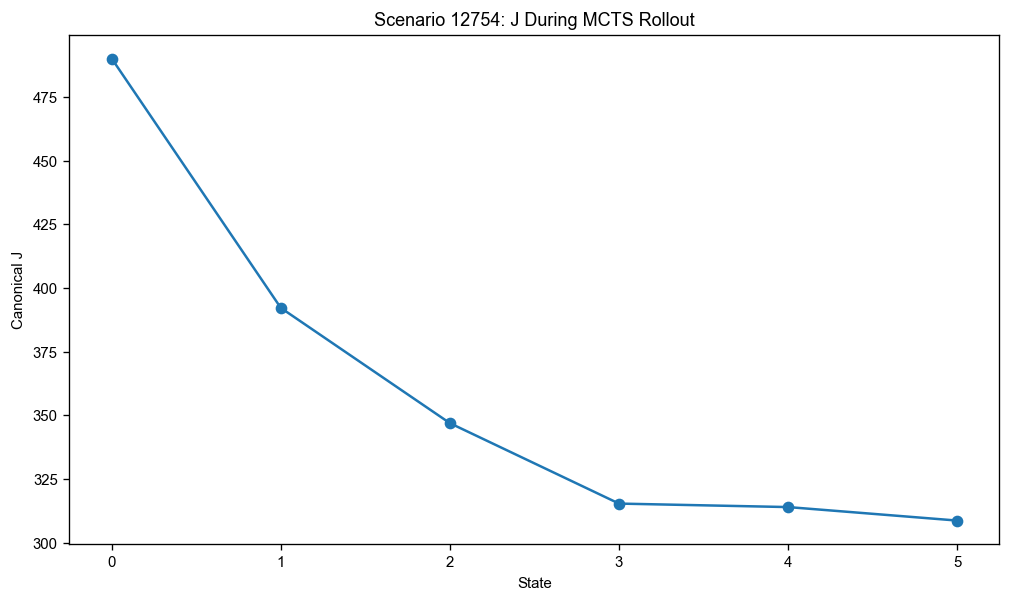

In [46]:
J_path = [
    scenario_trace.iloc[0]["J_before"],
    *scenario_trace["J_after"].tolist(),
]

fig, ax = plt.subplots()

ax.plot(
    range(len(J_path)),
    J_path,
    marker="o",
)

ax.set_title(f"Scenario {SCENARIO_ID}: J During MCTS Rollout")
ax.set_xlabel("State")
ax.set_ylabel("Canonical J")
ax.set_xticks(range(len(J_path)))

plt.show()

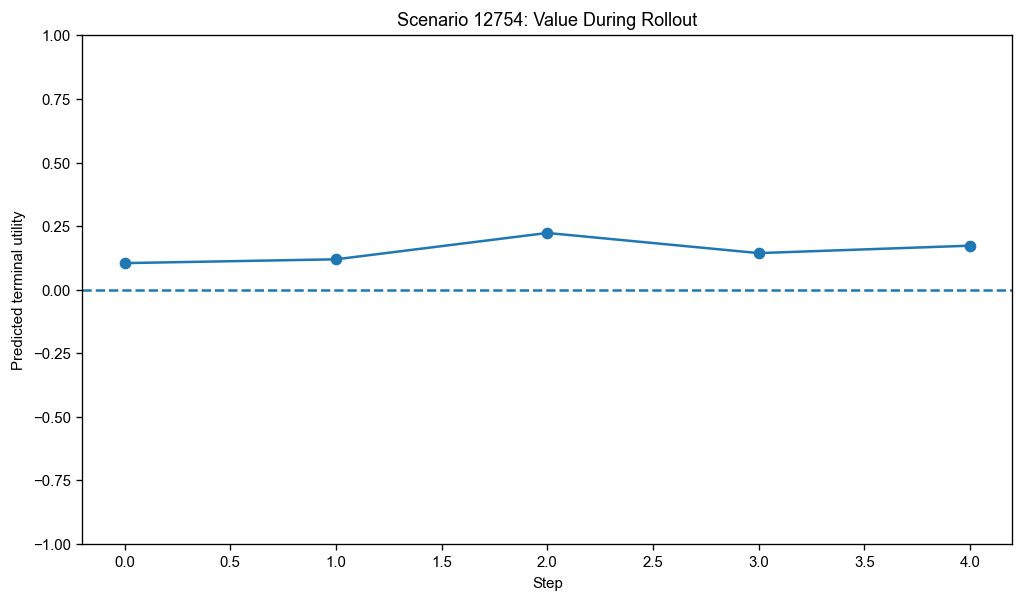

In [47]:
fig, ax = plt.subplots()

ax.plot(
    scenario_trace["step"],
    scenario_trace["predicted_value"],
    marker="o",
)

ax.axhline(0, linestyle="--")
ax.set_ylim(-1, 1)

ax.set_title(f"Scenario {SCENARIO_ID}: Value During Rollout")
ax.set_xlabel("Step")
ax.set_ylabel("Predicted terminal utility")

plt.show()

## 14. End-to-end benchmark

In [48]:
scenario_pool = (
    val_examples[
        [
            "scenario_id",
            "difficulty_class",
        ]
    ]
    .drop_duplicates()
)

evaluation_scenarios = pd.concat(
    [
        (
            scenario_pool[
                scenario_pool["difficulty_class"] == difficulty
            ]
            .sort_values("scenario_id")
            .head(EVAL_PER_DIFFICULTY)
        )
        for difficulty in DIFFICULTIES
    ],
    ignore_index=True,
)

display(evaluation_scenarios)

,scenario_id,difficulty_class
0,2,simple
1,12,simple
2,14,simple
3,19,simple
4,21,simple
5,23,simple
6,25,simple
7,33,simple
8,39,simple
9,43,simple


In [49]:
evaluation_rows = []

started = time.perf_counter()

for index, row in evaluation_scenarios.iterrows():
    scenario_id = int(row["scenario_id"])

    result, _ = run_mcts_episode(
        scenario_id
    )

    result["difficulty_class"] = row[
        "difficulty_class"
    ]

    evaluation_rows.append(
        result
    )

    print(
        f"[{index + 1:02d}/{len(evaluation_scenarios):02d}] "
        f"scenario={scenario_id:<6} "
        f"{row['difficulty_class']:<6} "
        f"J={result['Jfinal']:8.2f} "
        f"switches={result['switches']} "
        f"redispatch={result['redispatch_l1_mw']} "
        f"validated={result['terminal_validated']}"
    )

eval_results = pd.DataFrame(
    evaluation_rows
)

print()
print(
    f"Total time: "
    f"{time.perf_counter() - started:.1f} s"
)

display(eval_results)

[01/30] scenario=2      simple J=    5.00 switches=2 redispatch=0.06751415702076444 validated=True
[02/30] scenario=12     simple J=    5.36 switches=2 redispatch=0.0466280665357263 validated=True
[03/30] scenario=14     simple J=    2.00 switches=2 redispatch=0.1299882083644671 validated=True
[04/30] scenario=19     simple J=    4.00 switches=2 redispatch=0.18540601795114886 validated=True
[05/30] scenario=21     simple J=    6.00 switches=2 redispatch=0.06773024143301765 validated=True
[06/30] scenario=23     simple J=   26.19 switches=3 redispatch=0.0362002626353407 validated=True
[07/30] scenario=25     simple J=   13.74 switches=1 redispatch=0.0719640343931504 validated=True
[08/30] scenario=33     simple J=    4.00 switches=1 redispatch=0.08829021385701713 validated=True
[09/30] scenario=39     simple J=    4.00 switches=1 redispatch=0.094907399089352 validated=True
[10/30] scenario=43     simple J=    4.00 switches=1 redispatch=0.08867601565984438 validated=True
[11/30] scenario

,scenario_id,J0,Jfinal,delta_J,steps,switches,topology_secure,hard_overload_free,redispatch_validated,redispatch_l1_mw,terminal_validated,final_max_loading_%,final_hard_overloads,difficulty_class
0,2,43.522102,5.000008,38.522095,3,2,False,True,True,0.067514,True,99.987418,0,simple
1,12,50.630316,5.357746,45.272570,3,2,False,True,True,0.046628,True,99.534394,0,simple
2,14,51.994619,2.000005,49.994614,3,2,False,True,True,0.129988,True,99.458973,0,simple
3,19,54.962381,4.000005,50.962376,3,2,False,True,True,0.185406,True,99.999965,0,simple
4,21,52.514827,6.000011,46.514816,3,2,False,True,True,0.067730,True,99.999998,0,simple
5,23,59.564145,26.185337,33.378808,4,3,False,True,True,0.036200,True,100.092000,0,simple
6,25,51.400508,13.738790,37.661719,2,1,False,True,True,0.071964,True,100.369395,0,simple
7,33,52.846136,4.000006,48.846130,2,1,False,True,True,0.088290,True,99.999911,0,simple
8,39,40.561775,4.000007,36.561768,2,1,False,True,True,0.094907,True,92.598511,0,simple
9,43,53.241326,4.000008,49.241318,2,1,False,True,True,0.088676,True,99.988473,0,simple


## 15. End-to-end summary

In [50]:
def summarize(df):
    return pd.Series(
        {
            "Scenarios": len(df),
            "Validated, %": 100 * df["terminal_validated"].mean(),
            "Hard-overload-free, %": 100 * df["hard_overload_free"].mean(),
            "Topology secure, %": 100 * df["topology_secure"].mean(),
            "Mean J0": df["J0"].mean(),
            "Mean Jfinal": df["Jfinal"].mean(),
            "Mean delta J": df["delta_J"].mean(),
            "Mean switches": df["switches"].mean(),
            "Mean redispatch, MW": pd.to_numeric(
                df["redispatch_l1_mw"],
                errors="coerce",
            ).mean(),
            "Mean final loading, %": df["final_max_loading_%"].mean(),
        }
    )


end_to_end_summary = pd.concat(
    [
        summarize(eval_results).rename("all"),
        *[
            summarize(
                eval_results[
                    eval_results["difficulty_class"] == difficulty
                ]
            ).rename(difficulty)
            for difficulty in DIFFICULTIES
        ],
    ],
    axis=1,
).T

display(end_to_end_summary.round(2))

,Scenarios,"Validated, %","Hard-overload-free, %","Topology secure, %",Mean J0,Mean Jfinal,Mean delta J,Mean switches,"Mean redispatch, MW","Mean final loading, %"
all,30.0,80.0,56.67,0.0,320.39,231.46,88.93,3.53,135.05,122.91
simple,10.0,100.0,100.00,0.0,51.12,7.43,43.70,1.70,0.09,99.20
medium,10.0,90.0,60.00,0.0,214.61,120.50,94.11,4.00,127.20,119.93
hard,10.0,50.0,10.00,0.0,695.45,566.47,128.98,4.90,371.79,149.61


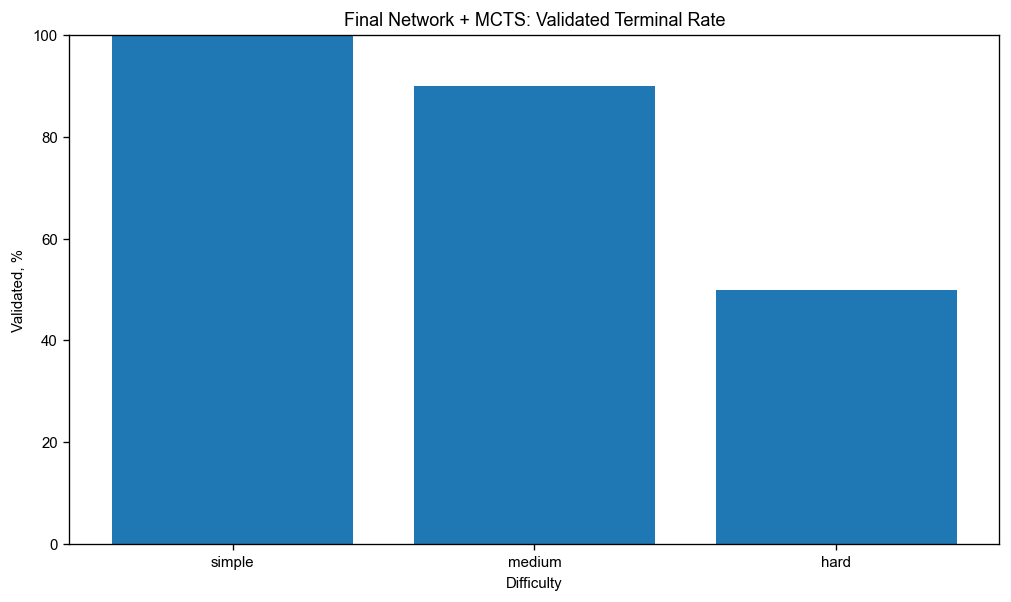

In [51]:
validated = (
    100
    * eval_results
    .groupby("difficulty_class")["terminal_validated"]
    .mean()
    .reindex(DIFFICULTIES)
)

fig, ax = plt.subplots()

ax.bar(
    validated.index,
    validated.values,
)

ax.set_title("Final Network + MCTS: Validated Terminal Rate")
ax.set_xlabel("Difficulty")
ax.set_ylabel("Validated, %")
ax.set_ylim(0, 100)

plt.show()

,Initial,Final
difficulty_class,,
simple,51.12,7.43
medium,214.61,120.50
hard,695.45,566.47


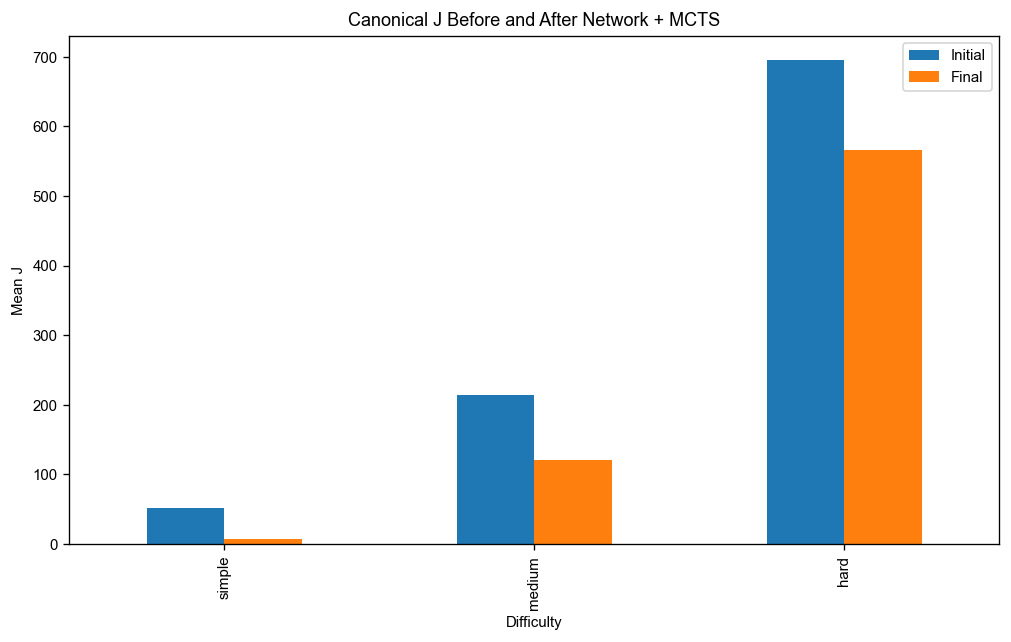

In [52]:
J_summary = (
    eval_results
    .groupby("difficulty_class")
    .agg(
        Initial=("J0", "mean"),
        Final=("Jfinal", "mean"),
    )
    .reindex(DIFFICULTIES)
)

display(J_summary.round(2))

fig, ax = plt.subplots()

J_summary.plot(
    kind="bar",
    ax=ax,
)

ax.set_title("Canonical J Before and After Network + MCTS")
ax.set_xlabel("Difficulty")
ax.set_ylabel("Mean J")

plt.show()

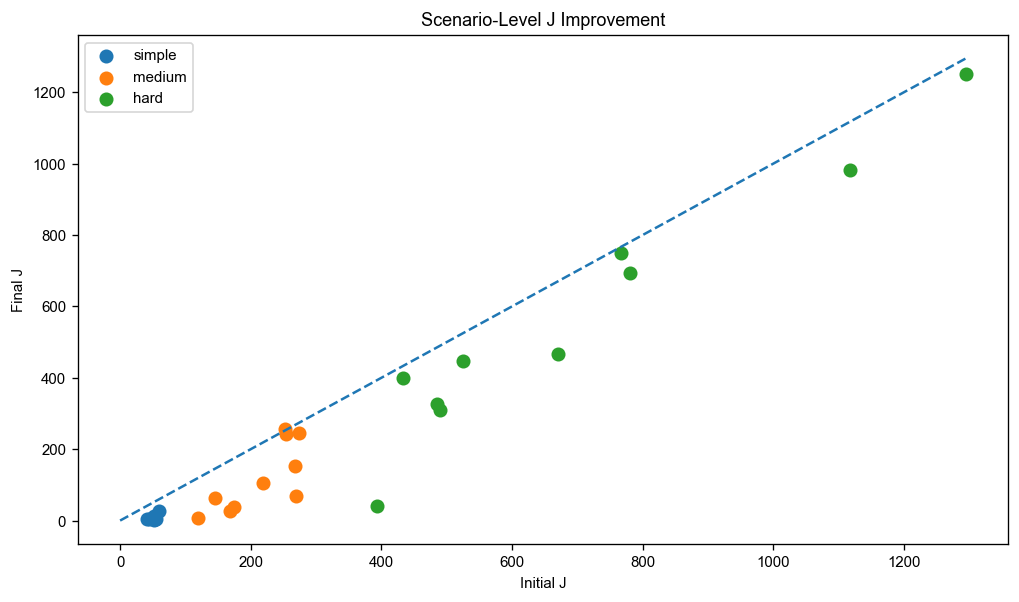

In [53]:
fig, ax = plt.subplots()

for difficulty in DIFFICULTIES:
    data = eval_results[
        eval_results["difficulty_class"] == difficulty
    ]

    ax.scatter(
        data["J0"],
        data["Jfinal"],
        s=55,
        label=difficulty,
    )

limit = max(
    eval_results["J0"].max(),
    eval_results["Jfinal"].max(),
)

ax.plot(
    [0, limit],
    [0, limit],
    linestyle="--",
)

ax.set_title("Scenario-Level J Improvement")
ax.set_xlabel("Initial J")
ax.set_ylabel("Final J")
ax.legend()

plt.show()

## 16. Network + MCTS vs Teacher

In [54]:
teacher_episode = (
    val_examples
    .sort_values(
        [
            "scenario_id",
            "step",
        ]
    )
    .groupby(
        "scenario_id",
        as_index=False,
    )
    .first()
)

teacher_episode["teacher_redispatch_mw"] = np.where(
    teacher_episode["teacher_outcome"].eq("solved"),
    0.0,
    teacher_episode["redispatch_l1_mw"],
)

comparison = eval_results.merge(
    teacher_episode[
        [
            "scenario_id",
            "teacher_selected_J",
            "teacher_selected_switch_count",
            "teacher_redispatch_mw",
            "teacher_outcome",
        ]
    ],
    on="scenario_id",
    how="left",
)

comparison["J_gap_to_teacher"] = (
    comparison["Jfinal"]
    - comparison["teacher_selected_J"]
)

comparison["switch_gap_to_teacher"] = (
    comparison["switches"]
    - comparison["teacher_selected_switch_count"]
)

comparison["redispatch_gap_to_teacher_mw"] = (
    comparison["redispatch_l1_mw"]
    - comparison["teacher_redispatch_mw"]
)

display(
    comparison[
        [
            "scenario_id",
            "difficulty_class",
            "Jfinal",
            "teacher_selected_J",
            "J_gap_to_teacher",
            "switches",
            "teacher_selected_switch_count",
            "switch_gap_to_teacher",
            "redispatch_l1_mw",
            "teacher_redispatch_mw",
            "redispatch_gap_to_teacher_mw",
            "terminal_validated",
        ]
    ].round(2)
)

,scenario_id,difficulty_class,Jfinal,teacher_selected_J,J_gap_to_teacher,switches,teacher_selected_switch_count,switch_gap_to_teacher,redispatch_l1_mw,teacher_redispatch_mw,redispatch_gap_to_teacher_mw,terminal_validated
0,2,simple,5.00,5.00,0.00,2,2,0,0.07,0.07,-0.00,True
1,12,simple,5.36,5.36,0.00,2,2,0,0.05,0.05,-0.00,True
2,14,simple,2.00,2.00,-0.00,2,2,0,0.13,0.13,-0.00,True
3,19,simple,4.00,4.00,0.00,2,2,0,0.19,0.19,-0.00,True
4,21,simple,6.00,6.00,-0.00,2,1,1,0.07,0.07,0.00,True
5,23,simple,26.19,17.88,8.31,3,3,0,0.04,0.11,-0.07,True
6,25,simple,13.74,13.74,0.00,1,1,0,0.07,0.07,0.00,True
7,33,simple,4.00,4.00,0.00,1,1,0,0.09,0.09,-0.00,True
8,39,simple,4.00,4.00,0.00,1,1,0,0.09,0.09,0.00,True
9,43,simple,4.00,4.00,0.00,1,1,0,0.09,0.09,0.00,True


In [55]:
teacher_gap = (
    comparison
    .groupby("difficulty_class")
    .agg(
        scenarios=("scenario_id", "size"),
        mean_J_gap=("J_gap_to_teacher", "mean"),
        median_J_gap=("J_gap_to_teacher", "median"),
        mean_switch_gap=("switch_gap_to_teacher", "mean"),
        mean_redispatch_gap_mw=(
            "redispatch_gap_to_teacher_mw",
            "mean",
        ),
        network_validated_rate=(
            "terminal_validated",
            "mean",
        ),
    )
    .reindex(DIFFICULTIES)
)

teacher_gap["network_validated_rate"] *= 100

display(teacher_gap.round(2))

,scenarios,mean_J_gap,median_J_gap,mean_switch_gap,mean_redispatch_gap_mw,network_validated_rate
difficulty_class,,,,,,
simple,10,0.83,0.00,0.1,-0.01,100.0
medium,10,-4.77,0.00,1.6,-4.24,90.0
hard,10,15.12,20.62,0.3,-15.83,50.0


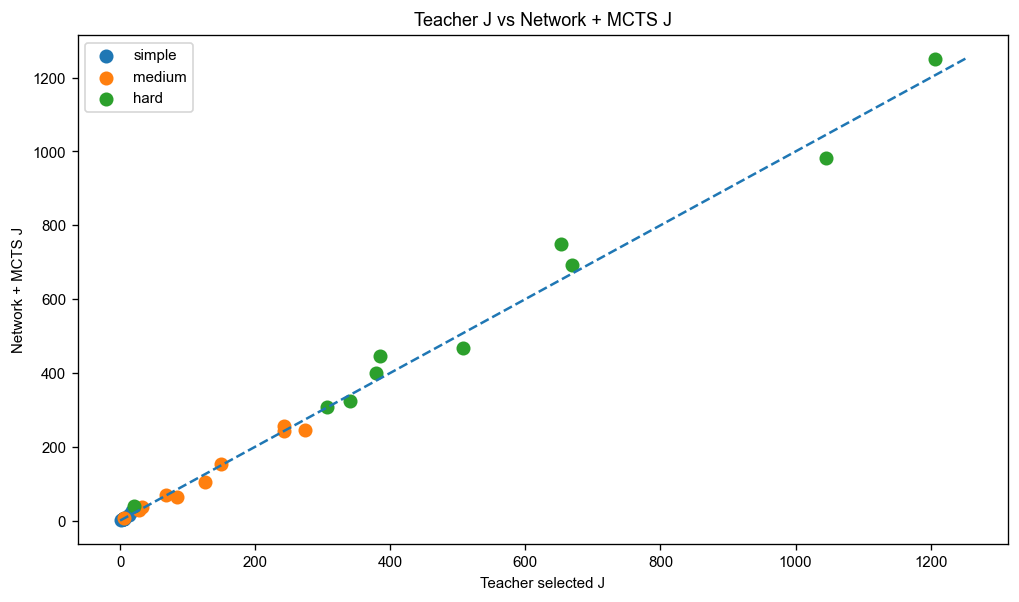

In [56]:
fig, ax = plt.subplots()

for difficulty in DIFFICULTIES:
    data = comparison[
        comparison["difficulty_class"] == difficulty
    ]

    ax.scatter(
        data["teacher_selected_J"],
        data["Jfinal"],
        s=55,
        label=difficulty,
    )

limit = max(
    comparison["teacher_selected_J"].max(),
    comparison["Jfinal"].max(),
)

ax.plot(
    [0, limit],
    [0, limit],
    linestyle="--",
)

ax.set_title("Teacher J vs Network + MCTS J")
ax.set_xlabel("Teacher selected J")
ax.set_ylabel("Network + MCTS J")
ax.legend()

plt.show()

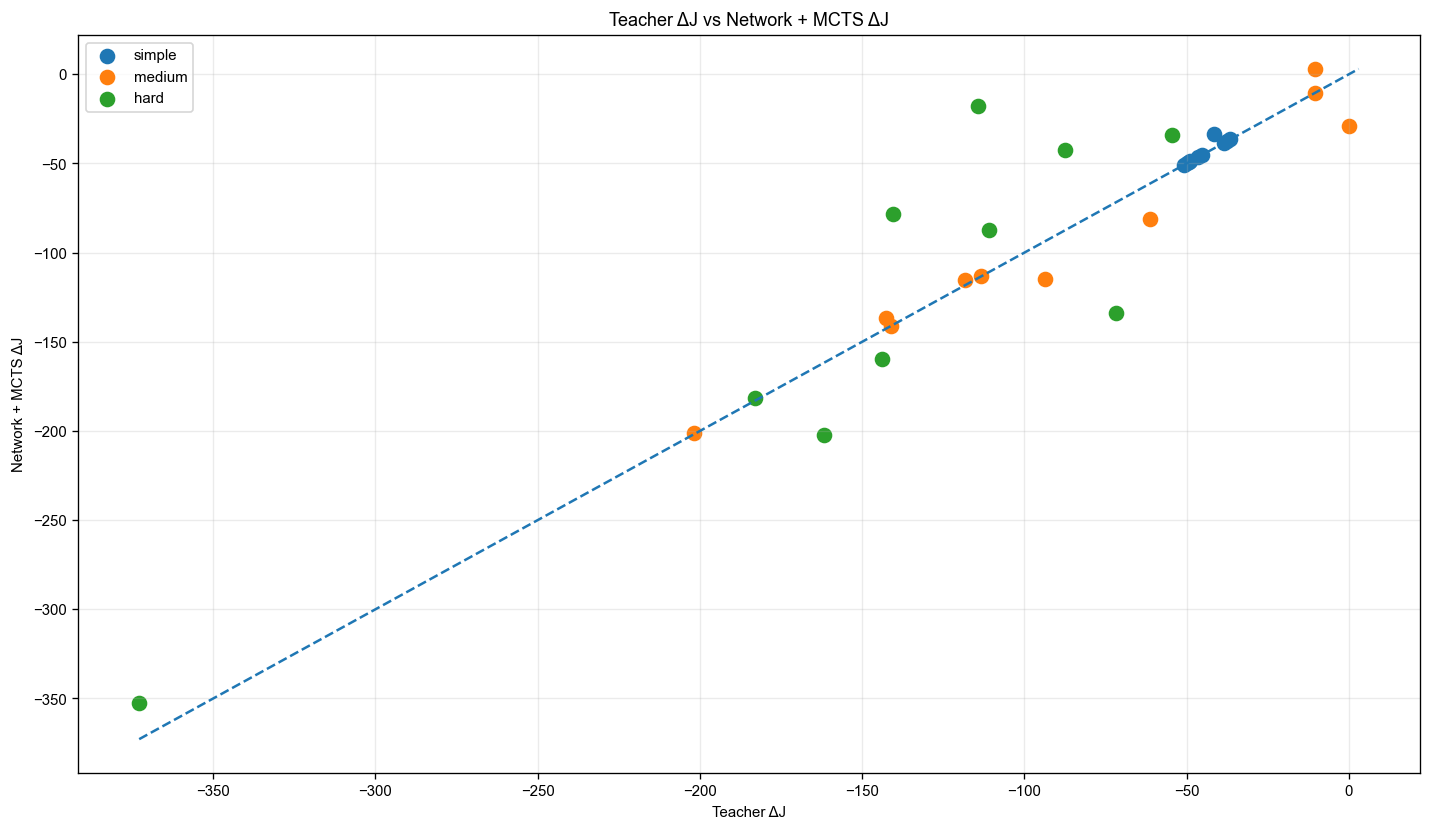

In [57]:
# Teacher ΔJ vs Network + MCTS ΔJ

delta_comparison = comparison.copy()

delta_comparison["teacher_delta_J"] = (
    delta_comparison["teacher_selected_J"]
    - delta_comparison["J0"]
)

delta_comparison["network_delta_J"] = (
    delta_comparison["Jfinal"]
    - delta_comparison["J0"]
)

plt.figure(figsize=(12, 7))

for difficulty in ["simple", "medium", "hard"]:
    part = delta_comparison[
        delta_comparison["difficulty_class"] == difficulty
    ]

    plt.scatter(
        part["teacher_delta_J"],
        part["network_delta_J"],
        s=70,
        label=difficulty,
    )

values = np.concatenate([
    delta_comparison["teacher_delta_J"].to_numpy(),
    delta_comparison["network_delta_J"].to_numpy(),
])

limit_min = values.min()
limit_max = values.max()

plt.plot(
    [limit_min, limit_max],
    [limit_min, limit_max],
    "--",
)


plt.xlabel("Teacher ΔJ")
plt.ylabel("Network + MCTS ΔJ")
plt.title("Teacher ΔJ vs Network + MCTS ΔJ")

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Что смотреть в первую очередь

**Value Head**

- R² / Pearson / Spearman;
- `Prediction std` против `Target std`;
- отдельно `hard`.

**Policy Head**

- Top-1 / Top-3 / Top-5;
- `Switch exact`;
- Teacher-action rank;
- отдельно `hard`.

**Практическое качество**

- `J0 -> Jfinal`;
- validated terminal rate;
- hard-overload-free rate;
- redispatch MW;
- switch count;
- gap к Teacher.

Для AlphaZero-подобной схемы policy Top-5 особенно полезен: MCTS не обязан брать
чистый argmax сети, policy используется как prior поиска.